# Project A: Three suns and a planet
**Draft checkpoint:** in class, Wed Nov 4 &nbsp;·&nbsp; **Submit:** this notebook on Canvas by Sun Nov 15, 11:59 pm &nbsp;·&nbsp; **Defence:** in class, Mon Nov 16

<img src="attachment:three_body.gif" width="300" alt="Animation of three equal masses, released from rest, moving under their mutual gravity; their centre of mass stays fixed">

<span style="font-size:0.8em">Animation: “Three-body Problem Animation with COM” by Dnttllthmmnm, Wikimedia Commons, CC BY-SA 4.0.</span>

One sun and a planet: Kepler solved that in 1609. Add two more suns and no formula gives you the orbits. A computer can follow them step by step, but small errors grow fast, so it cannot see far ahead. Can a planet survive there, and where?

## The system
Three suns and one planet move in a plane under Newtonian gravity. Each body feels the pull of all the others:

$$\vec a_{i} = -\sum_{j \neq i} G m_j\,\frac{\vec r_i - \vec r_j}{|\vec r_i - \vec r_j|^3}$$

Convenient units are astronomical units (AU), years and solar masses. In these units $G = 4\pi^2$, and the Earth orbits the Sun at 1 AU with a period of 1 year. An Earth-like planet has a mass of $3\times10^{-6}$ solar masses.

**Your analytic checks: Kepler and conservation.**
* A planet of negligible mass moves around one sun of mass $M$ on an ellipse. On a circle of radius $r$ its speed is $\sqrt{GM/r}$. Every orbit obeys Kepler's third law, $T^2 = a^3/M$, with the period $T$ in years and the semi-major axis $a$ (half the long axis) in AU.
* Two suns of masses $m_A$ and $m_B$ a distance $d$ apart can circle their common centre of mass. Their relative speed is then $\sqrt{G(m_A+m_B)/d}$, and each sun gets a share of it in proportion to the *other* sun's mass.
* This closed system obeys conservation laws: the total energy, the total momentum and the total angular momentum of all bodies stay constant.

## The core
1. **An N-body engine.** Complete `derivs(t, state, masses)` in the Code section, for $N$ bodies in a plane.
   * Keep the layout in the skeleton: all positions first, then all velocities. `state[:2*N].reshape(N, 2)` gives one row $(x, y)$ per body.
   * A body does not pull on itself.
   * Also write a function for the total energy: the kinetic energy of every body, plus one term $-G m_i m_j / r_{ij}$ for each pair. Count each pair once.
2. **One sun and one planet.** Put a sun of 1 solar mass at rest at the origin, and the planet at 1 AU on the $x$-axis. Give the planet mass 0 for now, so the sun stays where it is.
   * Start the planet at the circular speed. Measure the period with an event, as in Worksheet 12, and state how far it is from 1 year.
   * Start it at 1.2 times the circular speed. Measure the closest and farthest distance and the period, and check Kepler's third law as a number.
   * Run the second orbit for 100 years with `rtol` = $10^{-6}$, $10^{-9}$ and $10^{-12}$, once with the default method and once with `method='DOP853'`. Give the energy drift and `sol.nfev` for each. With mass 0 the planet's energy is 0, so use its energy per unit mass, $\tfrac12 v^2 - GM/r$.
   * Choose a method and tolerances from this test, give your reason, and use them from here on. Check `sol.status` after each run: with loose tolerances `solve_ivp` can stop early without an error.
3. **Three suns.** Suns A and B (1 solar mass each) circle each other 1 AU apart. Sun C (1 solar mass) circles the A+B pair at 15 AU, as if the pair were one sun of 2 solar masses. A and B start on the $x$-axis, and C on the positive $x$-axis.
   * Write a function `start(a_p, angle)` that returns the masses and the initial state for the three suns and a planet ($3\times10^{-6}$ solar masses). The planet starts on a circular orbit of radius `a_p` around the centre of A+B, at `angle` from the $x$-axis. You will reuse it in item 4 and in the question.
   * Shift all positions and velocities to the centre-of-mass frame. Otherwise the whole system drifts off your plots.
   * Run it for 250 years with the planet at 3 AU. Does the A–B distance stay at 1 AU? Does the pair's period agree with Kepler? State how well energy, momentum and angular momentum are conserved.
   * The planet holds only a tiny part of the total energy. Which motion does your energy check really test, and how could you test the planet's?
4. **The planet's story.** Start the planet at 5.6 AU, at an angle of 90°, and run for 600 years.
   * Plot the orbits for the first 100 years (equal axes), and the planet's distance from the A+B centre and from sun C against time.
   * Decide what "bound to the pair", "captured by sun C" and "escaped" mean, as rules you can compute. Hint: the planet's energy per unit mass relative to a sun or to the pair, $\tfrac12|\Delta\vec v|^2 - GM/|\Delta\vec r|$. Then tell the story with times.
   * Run it again with `rtol` 100 times smaller and 100 times larger. Which times in your story stay the same, which do not, and why is that not a bug?

## The question
**Where can a planet live?** Real planets circle pairs of suns, for example Kepler-16b. Close to the pair, the two suns shake the planet loose. Far out, sun C pulls it away. Find the inner and the outer edge of the zone where the planet survives.

Call the planet a survivor if it stays between $a_p/3$ and $3a_p$ from the A+B centre for 250 years. Use a terminal event to stop a run as soon as the planet leaves: this saves a lot of time. Try $a_p$ from 1.5 to 6.5 AU in steps of 0.25 AU, with 6 starting angles for each, and plot the fraction that survives against $a_p$. Why is one run per radius not enough? Holman & Wiegert (1999, *Astronomical Journal* 117, 621) fitted formulas for the stable zones of planets in binary star systems. Find the formula for a planet around both suns of a pair (A+B) and the one for a planet around one sun of a pair (here: A+B as one sun, with C as its partner), and compare their edges with yours. Then move sun C to 10 AU and to 20 AU. How do the two edges move? Finally, check one radius near each edge with a smaller `rtol`: does your verdict change? Each 250-year run should take a few seconds at most. If one takes minutes, check your method and whether the planet passed very close to a sun.

## Minimum expectation and going further
**Minimum:** everything in the core and the question, with each comparison to a known answer stated as a number; your rules for "bound", "captured" and "escaped"; your method and tolerances with a reason; the brief complete; the notebook runs top to bottom.

**Going further:** starlight and a habitable zone, if each sun shines like ours · unequal suns or eccentric orbits · a planet that circles only one sun of the pair · a planet orbiting backwards · a known three-body orbit, the figure-eight (Chenciner & Montgomery 2000) · going 3D (below)

**Going 3D.** Tilt the planet's orbit out of the plane of the suns. What can a tilted planet do that a flat one cannot? Some help to get started:
* Store the positions as an array of shape (N, dim). Then going from 2D to 3D changes one number. A 3D run with zero tilt must reproduce your 2D run; compare on a run that is not chaotic.
* A setup where something happens: the planet on a circular orbit at 1 AU around one sun, and the other two suns as a pair 1 AU apart, about 10 AU away. Try several tilts between 0° and 80°.
* To tilt the orbit, turn the planet's starting velocity out of the plane and keep its speed. Adding a vertical velocity on top makes the planet too fast.
* Measure the tilt and the shape of the planet's orbit relative to its own sun, not the centre of mass. The tilt follows from the direction of $\Delta\vec r \times \Delta\vec v$, the planet's position and velocity relative to that sun.
* The effects are slow. Run for hundreds to a few thousand years.

## How you are assessed
Your notebook and a short individual defence count together. The rubric, the defence and the checkpoint are described on the Canvas page [**Project A: how you are assessed**](https://canvas.ubc.ca/courses/195654/pages/project-a-how-you-are-assessed). Read it before you start.

---
# Your brief
Keep the brief to about one page: the sections below plus **one** key figure that answers your question. Your validation and other plots belong in the Code section below. Everything after the brief is your code, and it must run from top to bottom (Kernel → Restart & Run All) and produce that figure.

## This takes longer than 5 minutes to run (on JupyterOpen)

## 1. Research question

In a 4-Body-System consisting of 3 Suns and 1 Planet, at what starting radius away from a binary star system does the planet remain in a long-term stable orbit of 250 years, given all bodies initialize with circular velocity?

## 2. Model and method

I modelled the system as point masses moving in a plane under Newtonian gravity. I used AU, years and solar masses, so $G = 4\pi^2\,\mathrm{AU^3}\,M_\odot^{-1}\,\mathrm{yr^{-2}}$. For each body $i$, with position $\mathbf r_i$ and velocity $\mathbf v_i$, the equations are

$$
\frac{d\mathbf r_i}{dt} = \mathbf v_i, \qquad


\frac{d\mathbf v_i}{dt} = G\sum_{j\ne i} m_j \frac{\mathbf r_j - \mathbf r_i}{|\mathbf r_j - \mathbf r_i|^3}.

$$

The state vector stores all positions first and then all velocities: $[x_0,y_0,x_1,y_1,\ldots,v_{x,0},v_{y,0},v_{x,1},v_{y,1},\ldots]$. The three suns have masses $1\,M_\odot$ and the planet has mass $3\times10^{-6}\,M_\odot$. Suns A and B begin 1 AU apart with opposite tangential velocities, while C begins $15$ AU away with the approximate circular speed $\sqrt{G(M_A+M_B)/15}$. The planet begins at radius $a_p$ from the A+B centre at the selected angle, with tangential speed $\sqrt{G(M_A+M_B)/a_p}$. These initial conditions assume initially circular motion between A+B, Planet and A+B, and C and A_B. Bodies are treated as point masses.

I integrated the first-order system with scipy.integrate.solve_ivp. I used the default RK45 method with rtol=10^{-10} and the default absolute tolerance. The survival runs use a terminal event that returns the minimum signed distance to the limits $a_p/3$ and $3a_p, thus integration stops when the planet first leaves that interval.

## 3. Validation

I checked the numerical model against analytical orbital results, conservation laws and solver/tolerance comparisons.

**Analytical orbital checks.** For a massless planet orbiting a $1\,M_\odot$ sun, the circular speed is
$$v=\sqrt{GM/r},$$
and Kepler's third law is $T^2=a^3/M$. With $a=1$ AU and $M=1\,M_\odot$, the predicted period is $1$ year. The event-detected numerical period was $0.99999997$ years, differing by only $3.44\times10^{-8}$ years. I then started the planet at $1.2$ times the circular speed, producing an ellipse. Using the vis-viva equation and Kepler's Third Law the analytical period was predicted to be $T=2.3862610885$ years. The numerical period was $2.3862613483$ years, a difference of $2.598\times10^{-7}$ years.

**Solver and tolerance checks.** I integrated the 100-year elliptical test with the default RK45 method. Every run had sol.status = 0 (thus reaching desired final time). The final fractional energy drift was 0.0072% for rtol = 1e-10.

**Three-sun orbital checks.** For the equal-mass A+B pair separated by 1 AU, Kepler's law predicts
$$T_{AB}=\sqrt{\frac{a_{AB}^3}{m_A+m_B}}=\frac{1}{\sqrt{2}}=0.70711\,\mathrm{yr}.$$
The numerical A-B periods were $0.70697$ years initially, $0.70529$ years finally, with a minimum of $0.70463$ and a maximum of $0.70779$ years. The A-B separation began at 1 AU and varied only from 0.99652 to 1.00182 AU. The small variation is expected from perturbations by C and the planet, together with numerical error.

**Conservation checks.** For the full A, B, C and planet system over 250 years, I calculated the total energy
$$E=\sum_i\frac12m_i|\mathbf v_i|^2-\sum_{i<j}\frac{Gm_im_j}{r_{ij}},$$
the total momentum $\mathbf P=\sum_i m_i\mathbf v_i$, and the planar angular momentum
$$L_z=\sum_i m_i(x_iv_{y,i}-y_iv_{x,i}).$$
The fractional energy change was 0.1953%, the fractional angular-momentum change was 0.0186%, and the final momentum change had magnitude $3.26\times10^{-16}$. These small changes show that the numerical integration preserves the expected invariants well.

## 4. Key result
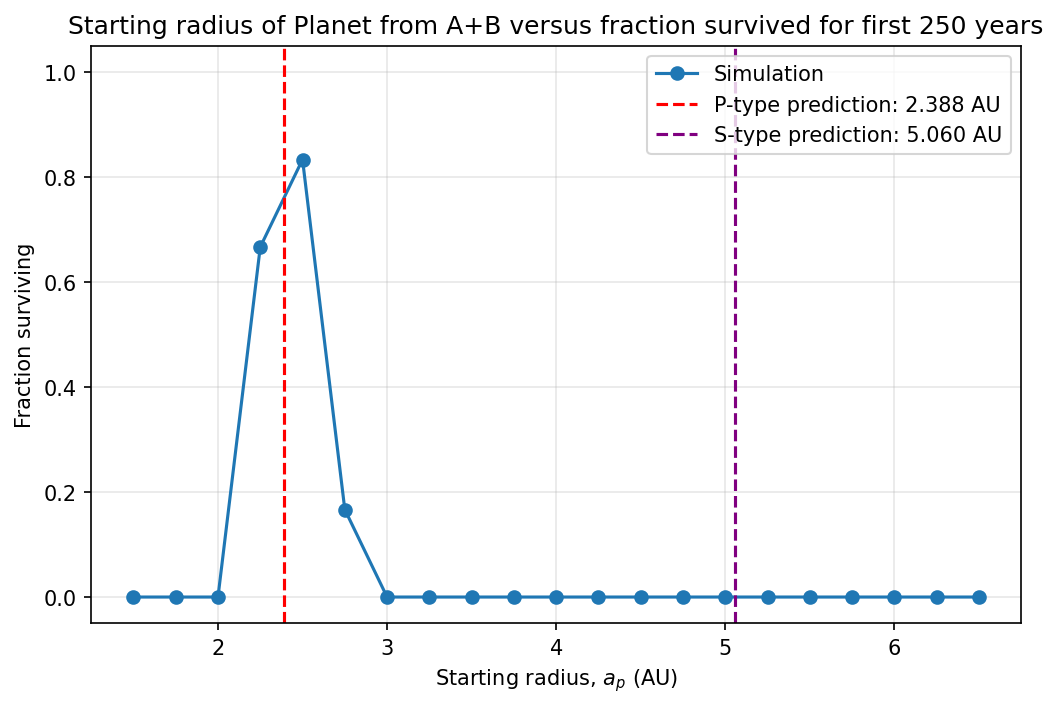

**Figure 1.** Fraction of the six tested starting angles that remain within $a_p/3$ and $3a_p$ of the A+B centre for the full 250-year integration, plotted against the planet's initial radius $a_p$. The transition at each edge is gradual because the three-body system is sensitive to the starting angle, so one radius can have both surviving and escaping runs.

## 5. Limitations and next step

Limitation: 250 years starting from the initial conditions is not enough time to determine a stable or surviving planet.

While the Holman--Wiegert P-type estimate of 2.39 AU agrees reasonably with the measured inner edge, its S-type estimate of 5.06 AU (for a Sun C at 15 AU) is farther out than my measured 250-year outer edge, because that fit describes long-term binary stability under idealized assumptions, whereas my test uses a finite 250-year interval and six discrete starting angles.

Moving C actually provides evidence of this. At 10 AU the perturbation is strong enough that no tested radius survives all 250 years, whereas at 20 AU the outer stable region expands and the simulations show 100% survival for the sampled radii from 2.5 to 3.25 AU.

The next step would be to measure for several thousand years, and see if there are any continous 250-year-long periods that exist in between those thousand years, or whether the planet settles into long-term stability. 

Another improvement would be to increase the number of starting angles, and decrease the radius increment in order to generate more tests and simulations. This would improve overall accuracy of the simulation.


## 6. Decision log
*Three choices you made, and what you rejected.*
1. I used the default RK45 method with rtol = 1e-10. While the DOP853 method does minimize my total energy drift more, (0.05306 vs 0.00957 from Part 2), the plotted graphs produced are much more jagged. I use t_eval with 5000 points in between to fix this jaggedness. However, this results in a higher total energy drift than simply using default RK45 method. Thus, I go with using RK45 with rtol = 1e-10, which minimizes total energy drift and still being computationally fast.

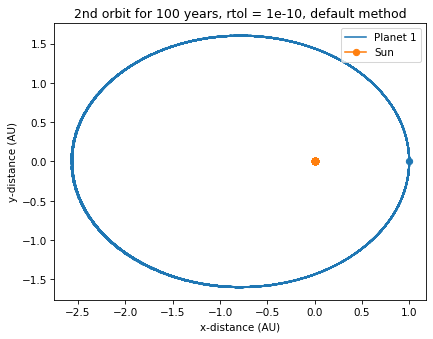
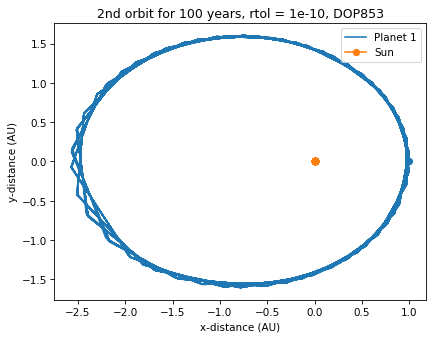

2. I classified the planet using its instantaneous specific orbital energies relative to A+B and C. I used
$$\epsilon_{AB}=\frac12|\Delta\mathbf v_{AB}|^2-\frac{G(M_A+M_B)}{|\Delta\mathbf r_{AB}|},\qquad
\epsilon_C=\frac12|\Delta\mathbf v_C|^2-\frac{GM_C}{|\Delta\mathbf r_C|}.$$ 
I called the planet **bound to A+B** when $\epsilon_{AB}<0$ and it was closer to the A+B centre than to C. I called it **captured by C** when $\epsilon_C<0$ and it was closer to C than to A+B. I called it **escaped** when both energies were positive. Negative specific energy is the two-body criterion for a bound orbit, while the distance comparison assigns the bound state to the nearer potential well. I rejected using distance alone because a close approach does not necessarily mean the planet is energetically bound, and I rejected using only one energy because the planet can be bound to both approximations at the same time during an encounter.

3. I tested six starting angles, $0^\circ,60^\circ,120^\circ,180^\circ,240^\circ$ and $300^\circ$, because it offers the best selection to test all directions using just 6 angles, with equal increments.

## 7. AI and help statement

Gor Nahapetyan (TA) helped me debug my N-Body-Engine, examining the jaggedness I was seeing being produced. It was fixed by altering the tolerances.

Sources (as referenced throughout the Code section of the notebook)
1. Physics LibreTexts, "The Vis-Viva Equation," https://phys.libretexts.org/Courses/Prince_Georges_Community_College/General_Physics_I%3A_Classical_Mechanics/57%3A__Celestial_Mechanics/57.10%3A_The_Vis_Viva_Equation. Used for the elliptical-orbit semimajor-axis and period check.
2. Oxford Physics, "Lecture 6: Mechanics Handout," https://users.physics.ox.ac.uk/~harnew/lectures/lecture6-mechanics-handout.pdf. Used for centre-of-mass transformations.
3. Physics LibreTexts, "Center of Mass of a Many-Body System," https://phys.libretexts.org/Bookshelves/Classical_Mechanics/Variational_Principles_in_Classical_Mechanics_(Cline)/02%3A_Review_of_Newtonian_Mechanics/2.07%3A_Center_of_Mass_of_a_Many-Body_System. Used for centre-of-mass formulas.
4. University of Edinburgh, angular momentum lecture notes, https://www2.ph.ed.ac.uk/~ldeldebb/docs/QM/lect8.pdf. Used for the planar angular-momentum formula.
5. Isaac Science, "Centre of Mass," https://isaacscience.org/concepts/cp_centre_mass. Used for the A+B centre-of-mass calculation.
6. Holman and Wiegert (1999), "Long-Term Stability of Planets in Binary Systems," *The Astronomical Journal*, 117, 621. ADS record: https://ui.adsabs.harvard.edu/abs/1999AJ....117..621H/abstract. Used for the analytical P-type and S-type stability-edge comparison.

# Going Further
I plotted all of the survival run tests, with com and non-com frame as well. You can visually see the ones which survive and don't survive by the amount of orbit lines, showing that the simulation ran for a longer time.

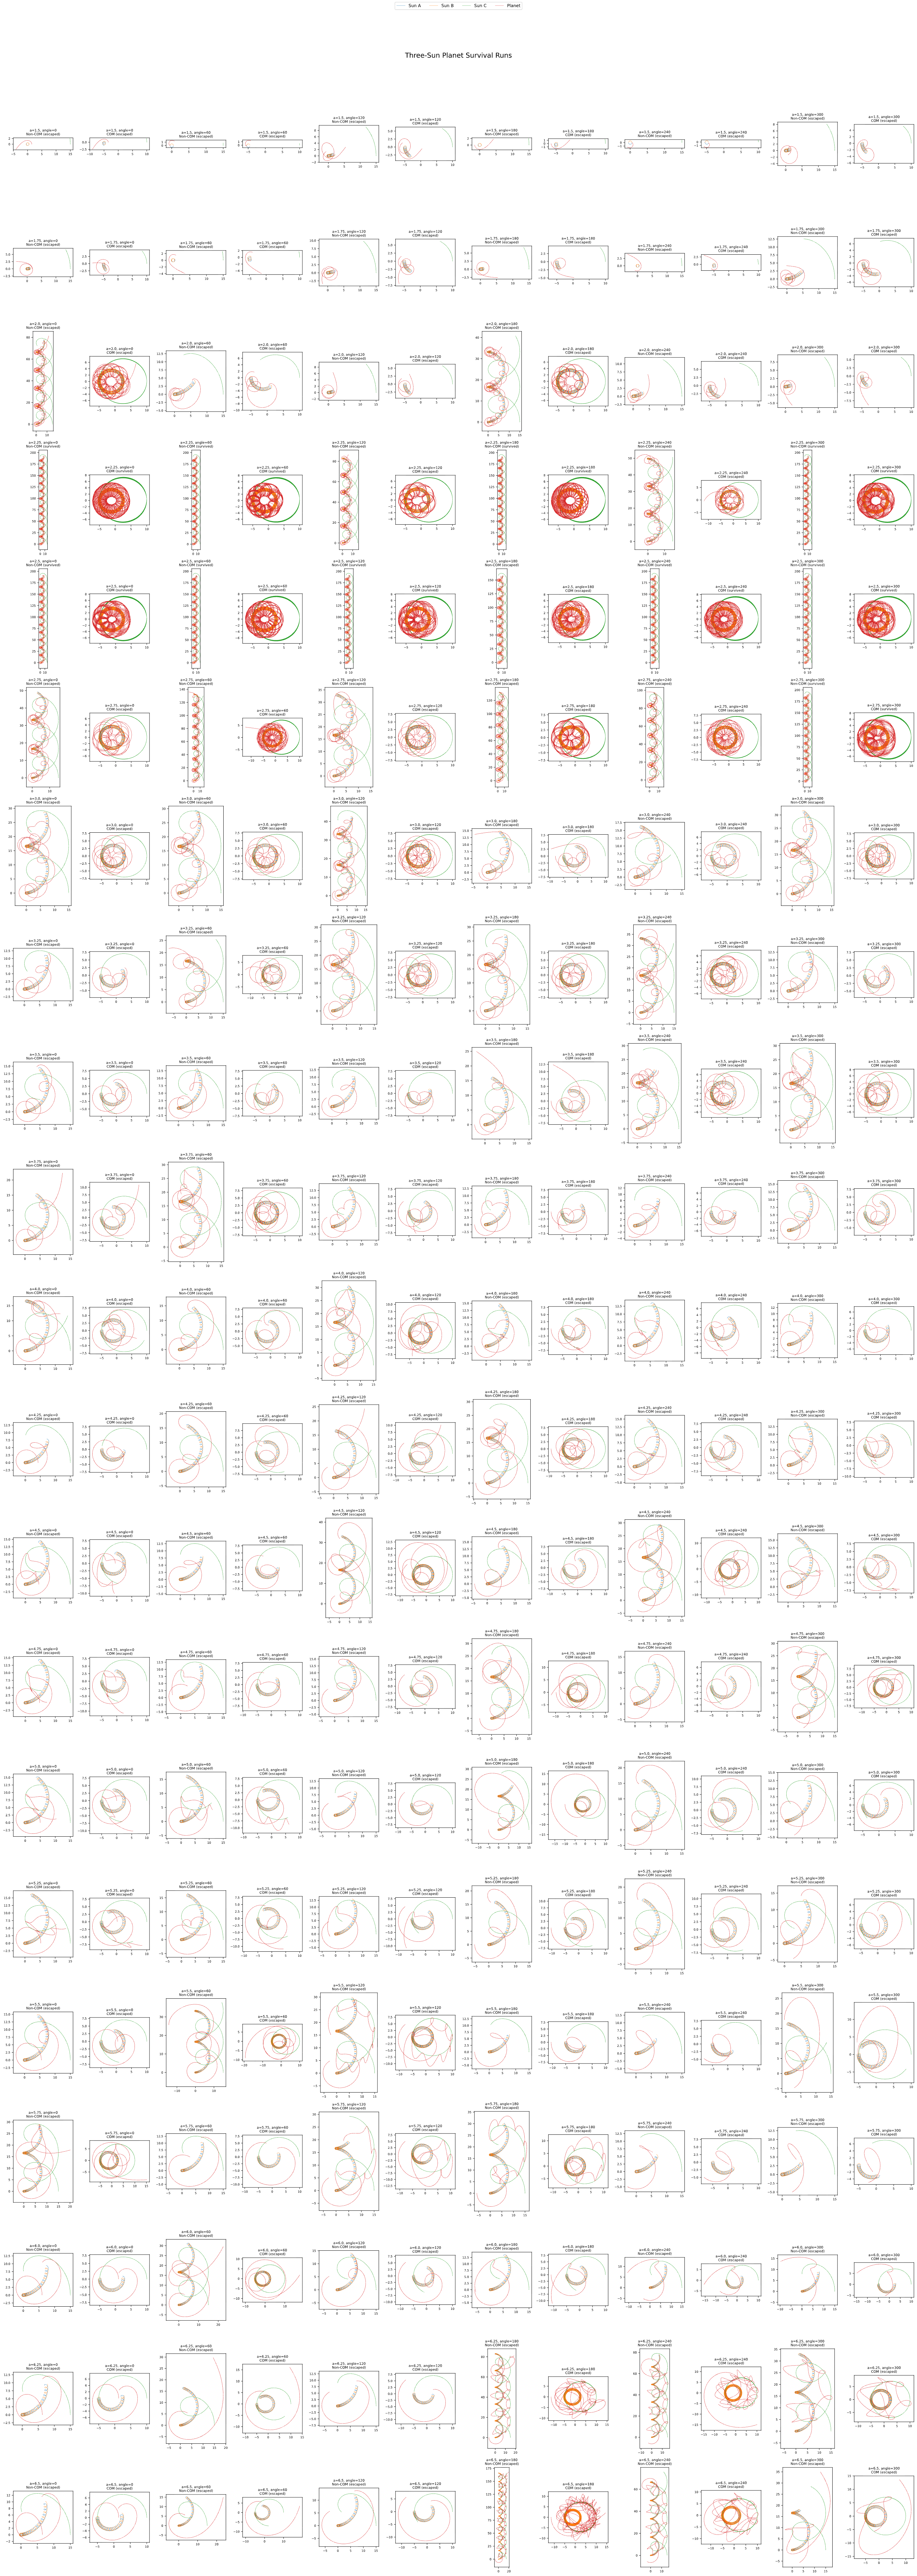

---
# Code


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from copy import copy
import matplotlib.animation as animation
plt.rcParams['figure.dpi'] = 125

## 1. An N-body Engine

### N-Body Engine

In [15]:
G = 4 * np.pi**2   # AU^3 / (solar mass * yr^2)


def derivs(t, state, masses):
    """Time derivative of state for N bodies in a plane, in AU, years and solar masses.

    state = [x0, y0, x1, y1, ..., vx0, vy0, vx1, vy1, ...]: all positions first, then all velocities.
    masses = array of the N masses.
    """
    N = len(masses)
    pos = state[:2*N].reshape(N, 2)
    vel = state[2*N:].reshape(N, 2)
    acc = np.zeros((N, 2))
    
    for i in range(0,N):
        pos_ij = pos[i] - pos
        r_ij = np.sqrt(pos_ij[:,0]**2+pos_ij[:,1]**2)

        r_ij[i] = np.inf
        
        acc_x = -G*masses*(pos_ij[:,0])/r_ij**3
        acc_y = -G*masses*(pos_ij[:,1])/r_ij**3
        acc[i] = (np.sum(acc_x), np.sum(acc_y))
    
    return np.concatenate([vel.ravel(), acc.ravel()])

### Total Energy Function

The total energy function has two modes, whether you are calculating for a 2 body system with one body of mass 0, or calculating with 3+ body system where all bodies have mass. If you calculate a 2 body system like in Part 2, you simply calculate the energy per unit mass of the massless planet, with $E=\frac{1}{2}v^2-\frac{GM}{r}$.

In [16]:
# Total Energy Function

def total_energy(state, masses, zero_mass = False, central_body_idx = 1):
    N = len(masses)
    pos = state[:2*N].reshape(N, 2)
    vel = state[2*N:].reshape(N, 2)
    energy = 0

    if zero_mass == True:
        i = 0 # this is the index of the massless planet
        j = central_body_idx
        M = masses[j] # M is the mass of the Sun (or central body)
        
        x_i, y_i = pos[i][0], pos[i][1]
        v_x, v_y = vel[i][0], vel[i][1]
        x_j, y_j = pos[j][0], pos[j][1]

        r_ij = np.sqrt((x_i-x_j)**2 + (y_i-y_j)**2)

        v = np.sqrt(v_x**2 + v_y **2)

        energy = 0.5 * v**2 - (G * M) / r_ij
    
        return energy
        
    else:
        for i in range(0,N):
            m_i = masses[i]
            x_i = pos[i][0]
            y_i = pos[i][1]
    
            v_x = vel[i][0]
            v_y = vel[i][1]
            for j in range(i+1,N):
                m_j = masses[j]
                x_j = pos[j][0]
                y_j = pos[j][1]
    
                r_ij = np.sqrt((x_i-x_j)**2 + (y_i-y_j)**2)
        
                energy += -G * m_i * m_j / r_ij
    
            energy += 0.5*m_i*(v_x**2 + v_y**2)
    
        return energy

## 2. One sun and one planet

### Circular Orbit

The planet's circular velocity is calculated by $v = \sqrt{\frac{GM}{r}}$, as given in the project description.

Since $G=4\pi^2$, $M=1$, and $r=1$, we have

$$v = \sqrt{\frac{4\pi^2 \cdot 1}{1}}=2\pi$$

In [17]:
state0 = np.array([
    1, 0, #Planet 1 pos
    0, 0, #Sun pos
    0, 2*np.pi, #Planet 1 vel
    0, 0  #Sun vel
])

M = 1 # Sun mass
m = 0 # Planet 1 mass

masses = np.array([
    m, # Planet 1 mass
    M # Sun mass
])
ti, tf = 0, 1

def period(t, state, *args):
    planet_y = state[1]
    return planet_y
period.direction = 1

sol = solve_ivp(derivs, (ti,tf), state0, atol = 1e-8, rtol = 1e-8, args=(masses,), events = period)

earth_x = sol.y[0]
earth_y = sol.y[1]

sun_x = sol.y[2]
sun_y = sol.y[3]

Using Kepler's Third Law, we have
$$T=\sqrt{\frac{a^3}{M}}=\sqrt{\frac{1^3}{1}}=1 \text{ year}$$

Thus, 1 year is the theoretical period.

In [18]:
print("Event triggered at t =", sol.t_events[0])

T_theory = 1

period_diff = np.abs(sol.t_events[0][-1] - T_theory)
print(f"Difference between {T_theory} year(s) (as calculated by Kepler's 3rd Law) and the period is {period_diff:0.10f} years.")

Event triggered at t = [0.         0.99999997]
Difference between 1 year(s) (as calculated by Kepler's 3rd Law) and the period is 0.0000000344 years.


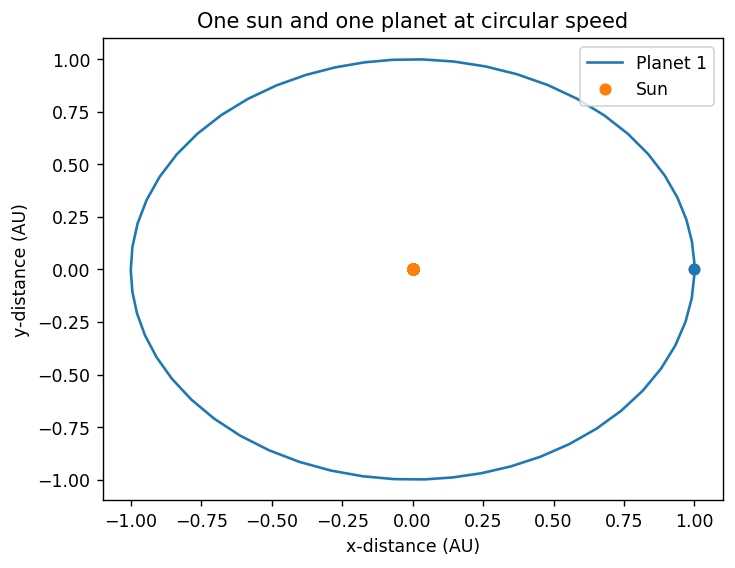

In [19]:
plt.plot(earth_x, earth_y, '-', label = "Planet 1")
plt.scatter(earth_x[0], earth_y[0])
plt.plot(sun_x, sun_y, 'o', label = "Sun")
plt.xlabel("x-distance (AU)")
plt.ylabel("y-distance (AU)")
plt.legend(loc="upper right")
plt.title("One sun and one planet at circular speed")
plt.show()

### 1.2x Circular orbit 

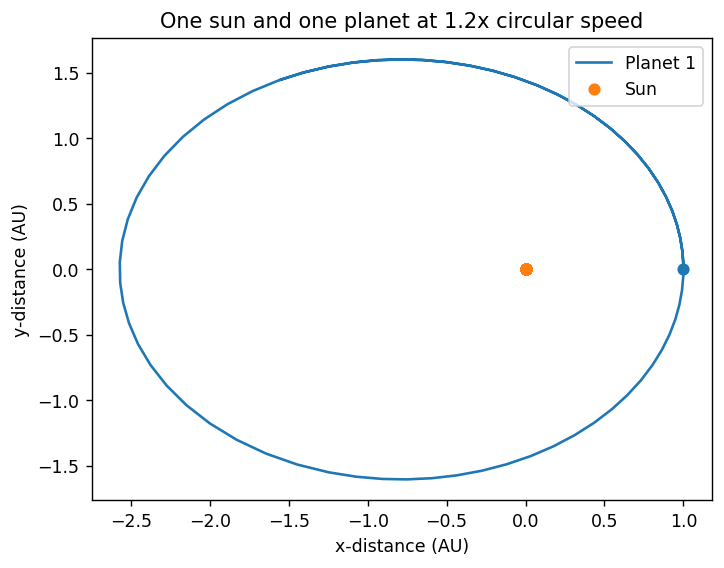

In [20]:
state0 = np.array([
    1, 0, #Planet 1 pos
    0, 0, #Sun pos
    0, 1.2*2*np.pi, #Planet 1 vel
    0, 0  #Sun vel
])

M = 1 # Sun mass
m = 0 # Planet 1 mass

masses = np.array([
    m, # Planet 1 mass
    M # Sun mass
])
ti, tf = 0, 3

def period(t, state, *args):
    planet_y = state[1]
    return planet_y
period.direction = 1

sol = solve_ivp(derivs, (ti,tf), state0, atol = 1e-8, rtol = 1e-8, args=(masses,), events = period)

earth_x = sol.y[0]
earth_y = sol.y[1]

sun_x = sol.y[2]
sun_y = sol.y[3]

plt.plot(earth_x, earth_y, '-', label = "Planet 1")
plt.scatter(earth_x[0], earth_y[0])
plt.plot(sun_x, sun_y, 'o', label = "Sun")
plt.xlabel("x-distance (AU)")
plt.ylabel("y-distance (AU)")
plt.legend(loc='upper right')
plt.title("One sun and one planet at 1.2x circular speed")
plt.show()

In [21]:
r = np.sqrt((earth_x - sun_x)**2 + (earth_y - sun_y)**2)
max_distance = np.max(r)
min_distance = np.min(r)

print(f"Maximum distance between the planet and sun is: {max_distance:0.3f} AU")
print(f"Minimum distance between the planet and sun is: {min_distance:0.3f} AU")

Maximum distance between the planet and sun is: 2.571 AU
Minimum distance between the planet and sun is: 1.000 AU


Calculting the analytical theoretical period of this orbit is obtained through using the vis visa<sup>1</sup> equation to calculate the semi-major axis, $a$.

The vis visa equation states that $$v=\sqrt{GM(\frac{2}{r}-\frac{1}{a})}$$ where $v$ is the orbital speed

Solving for $a$, we have 
$$
\begin{aligned}
a &= \left( \frac{2}{r} - \frac{v^2}{GM} \right)^{-1} \\
  &= \left( \frac{2}{1} - \frac{(2\cdot 1.2 \cdot \pi)^2}{4\pi^2} \right)^{-1} \\
  &\approx 1.78571 \text{ AU}
\end{aligned}
$$

Then using Kepler's Third Law we have:

$$
\begin{aligned}

T &= \sqrt{\frac{a^3}{M}} \\
  &= \sqrt{\frac{1.78571^3}{1}} \\
  &\approx 2.38626 \text{ years}
\end{aligned}
$$




1. https://phys.libretexts.org/Courses/Prince_Georges_Community_College/General_Physics_I%3A_Classical_Mechanics/57%3A__Celestial_Mechanics/57.10%3A_The_Vis_Viva_Equation

In [22]:
# calculating analytical period
a_an = (2/1 - (2*1.2*np.pi)**2/(4*np.pi**2))**-1
T_an = np.sqrt(a_an**3)

print(f"Analytical a = {a_an:0.10f} AU")
print(f"Analytical T = {T_an:0.10f} years")

Analytical a = 1.7857142857 AU
Analytical T = 2.3862610885 years


In [23]:
T_n = sol.t_events[0][-1]
print(f"Numerical T = {T_n:0.10f} years")
period_diff = np.abs(T_n - T_an)
print(f"Difference in analytical and numerical periods is: {period_diff : 0.10f} years")

Numerical T = 2.3862613483 years
Difference in analytical and numerical periods is:  0.0000002598 years


### Energy Drift function

This function utilizes the previously defined total_energy() function. 

In [24]:
def energy_drift(sol, masses, zero_mass = False):
    energies = []
    num_time = len(sol.t)

    for k in range(num_time):
        state_k = sol.y[:, k] #accessing the model state at the specific timestep we are currently at
        energies.append(total_energy(state_k, masses, zero_mass))

    energies = np.array(energies)

    energy_drift = np.abs((energies - energies[0]) / energies[0])

    print(f"Initial Energy: {energies[0]:.10f}")
    print(f"Final Energy: {energies[-1]:.10f}")
    print(f"Final Fractional Energy Drift: {energy_drift[-1]*100:0.4f}%")
    print(f"Max Fractional Energy Drift: {np.max(energy_drift):.10f}")
    print(f"Total Absolute Cumulative Energy Drift: {np.abs(np.sum(energy_drift)):.5f}")

    return energies

### Running orbit for 100 years, with rtol = 1e-6, 1e-8, 1e-10 and default method

In [25]:
plt.rcParams['figure.dpi'] = 75

----------------------------------------------------------------------------------------
Num of evals: 8960
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0594893582
Final Fractional Energy Drift: 0.0500%
Max Fractional Energy Drift: 0.0005004931
Total Absolute Cumulative Energy Drift: 0.28643


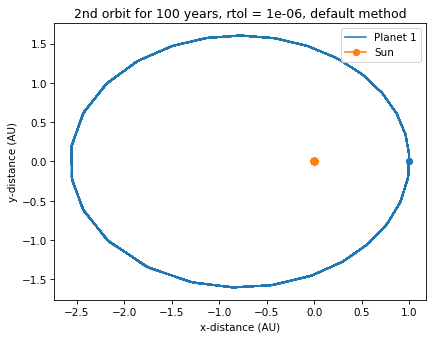

----------------------------------------------------------------------------------------
Num of evals: 10646
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0548160055
Final Fractional Energy Drift: 0.0078%
Max Fractional Energy Drift: 0.0000784510
Total Absolute Cumulative Energy Drift: 0.05625


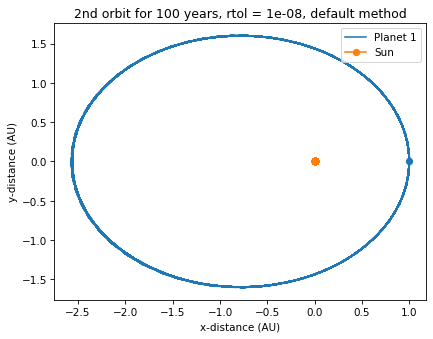

----------------------------------------------------------------------------------------
Num of evals: 10730
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0547556635
Final Fractional Energy Drift: 0.0072%
Max Fractional Energy Drift: 0.0000729562
Total Absolute Cumulative Energy Drift: 0.05306


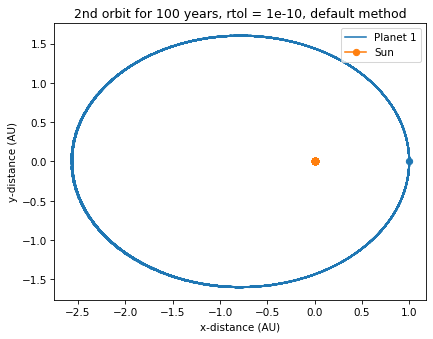

In [26]:
state0 = np.array([
    1, 0, #Planet 1 pos
    0, 0, #Sun pos
    0, 1.2*2*np.pi, #Planet 1 vel
    0, 0  #Sun vel
])

M = 1 # Sun mass
m = 0 # Planet 1 mass

masses = np.array([
    m, # Planet 1 mass
    M # Sun mass
])
ti, tf = 0, 100
t_eval = np.linspace(ti,tf, 10000)

tols = [1e-6, 1e-8, 1e-10]

for tol in tols:
    sol = solve_ivp(derivs, (ti,tf), state0, rtol = tol, args=(masses,))

    earth_x = sol.y[0]
    earth_y = sol.y[1]

    sun_x = sol.y[2]
    sun_y = sol.y[3]

    print("----------------------------------------------------------------------------------------")
    print(f"Num of evals: {sol.nfev}")
    print(f"Solution Status: {sol.status}")
    energy_drift(sol, masses, zero_mass = True)
    

    plt.plot(earth_x, earth_y, '-', label = "Planet 1")
    plt.scatter(earth_x[0], earth_y[0])
    plt.plot(sun_x, sun_y, '-o', label = "Sun")
    plt.xlabel("x-distance (AU)")
    plt.ylabel("y-distance (AU)")
    plt.legend(loc="upper right")
    plt.title(f"2nd orbit for 100 years, rtol = {tol}, default method")
    plt.show()

### Running orbit for 100 years, with rtol = 1e-6, 1e-8, 1e-10 and method DOP853

----------------------------------------------------------------------------------------
Num of evals: 8402
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0567172944
Final Fractional Energy Drift: 0.0250%
Max Fractional Energy Drift: 0.0002507472
Total Absolute Cumulative Energy Drift: 0.06387


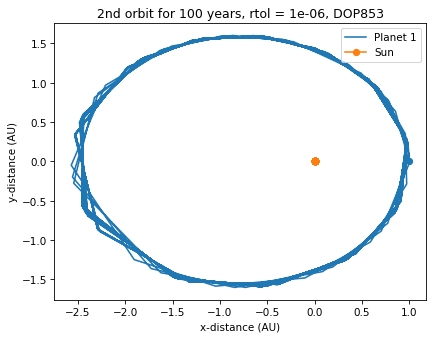

----------------------------------------------------------------------------------------
Num of evals: 9974
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0543341363
Final Fractional Energy Drift: 0.0034%
Max Fractional Energy Drift: 0.0000342329
Total Absolute Cumulative Energy Drift: 0.01012


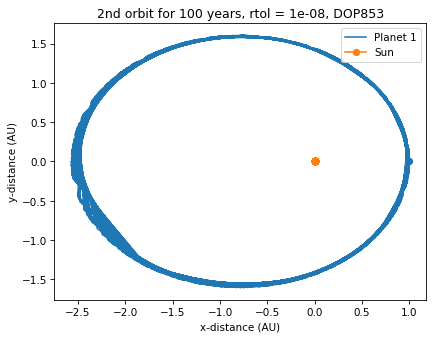

----------------------------------------------------------------------------------------
Num of evals: 10022
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0543107368
Final Fractional Energy Drift: 0.0032%
Max Fractional Energy Drift: 0.0000321186
Total Absolute Cumulative Energy Drift: 0.00957


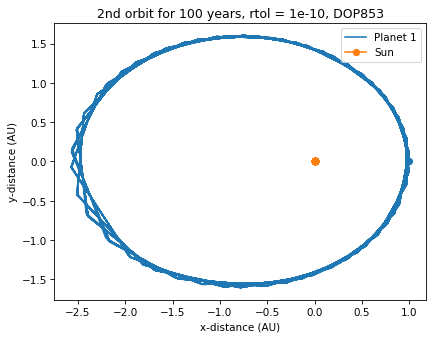

In [27]:
state0 = np.array([
    1, 0, #Planet 1 pos
    0, 0, #Sun pos
    0, 1.2*2*np.pi, #Planet 1 vel
    0, 0  #Sun vel
])

M = 1 # Sun mass
m = 0 # Planet 1 mass

masses = np.array([
    m, # Planet 1 mass
    M # Sun mass
])
ti, tf = 0, 100

tols = [1e-6, 1e-8, 1e-10]

for tol in tols:
    sol = solve_ivp(derivs, (ti,tf), state0, rtol = tol, args=(masses,), method = "DOP853")

    earth_x = sol.y[0]
    earth_y = sol.y[1]

    sun_x = sol.y[2]
    sun_y = sol.y[3]

    print("----------------------------------------------------------------------------------------")
    print(f"Num of evals: {sol.nfev}")
    print(f"Solution Status: {sol.status}")
    energy_drift(sol, masses, zero_mass = True)
    

    plt.plot(earth_x, earth_y, '-', label = "Planet 1")
    plt.scatter(earth_x[0], earth_y[0])
    plt.plot(sun_x, sun_y, '-o', label = "Sun")
    plt.xlabel("x-distance (AU)")
    plt.ylabel("y-distance (AU)")
    plt.legend(loc="upper right")
    plt.title(f"2nd orbit for 100 years, rtol = {tol}, DOP853")
    plt.show()

### Running orbit for 100 years, with rtol = 1e-6, 1e-8, 1e-10 and method DOP853, AND t_eval

----------------------------------------------------------------------------------------
Num of evals: 9914
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0567172944
Final Fractional Energy Drift: 0.0250%
Max Fractional Energy Drift: 0.0002610472
Total Absolute Cumulative Energy Drift: 0.63442


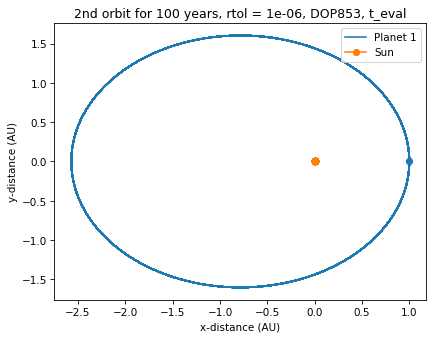

----------------------------------------------------------------------------------------
Num of evals: 11756
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0543341363
Final Fractional Energy Drift: 0.0034%
Max Fractional Energy Drift: 0.0000352087
Total Absolute Cumulative Energy Drift: 0.08509


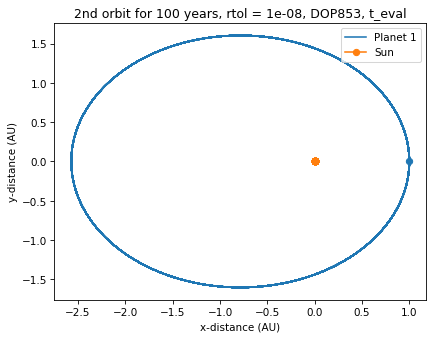

----------------------------------------------------------------------------------------
Num of evals: 11813
Solution Status: 0
Initial Energy: -11.0539569292
Final Energy: -11.0543107368
Final Fractional Energy Drift: 0.0032%
Max Fractional Energy Drift: 0.0000327652
Total Absolute Cumulative Energy Drift: 0.08004


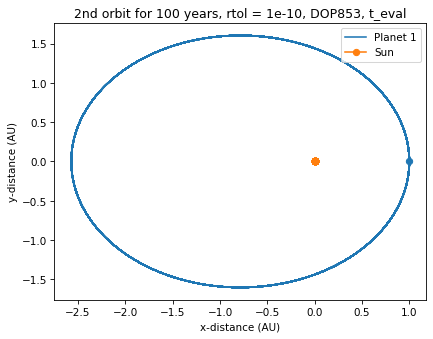

In [28]:
state0 = np.array([
    1, 0, #Planet 1 pos
    0, 0, #Sun pos
    0, 1.2*2*np.pi, #Planet 1 vel
    0, 0  #Sun vel
])

M = 1 # Sun mass
m = 0 # Planet 1 mass

masses = np.array([
    m, # Planet 1 mass
    M # Sun mass
])
ti, tf = 0, 100
t_eval = np.linspace(ti,tf, 5000)

tols = [1e-6, 1e-8, 1e-10]


for tol in tols:
    sol = solve_ivp(derivs, (ti,tf), state0, rtol = tol, args=(masses,), method = "DOP853", t_eval=t_eval)

    earth_x = sol.y[0]
    earth_y = sol.y[1]

    sun_x = sol.y[2]
    sun_y = sol.y[3]

    print("----------------------------------------------------------------------------------------")
    print(f"Num of evals: {sol.nfev}")
    print(f"Solution Status: {sol.status}")
    energy_drift(sol, masses, zero_mass = True)
    

    plt.plot(earth_x, earth_y, '-', label = "Planet 1")
    plt.scatter(earth_x[0], earth_y[0])
    plt.plot(sun_x, sun_y, '-o', label = "Sun")
    plt.xlabel("x-distance (AU)")
    plt.ylabel("y-distance (AU)")
    plt.legend(loc="upper right")
    plt.title(f"2nd orbit for 100 years, rtol = {tol}, DOP853, t_eval")
    plt.show()

## 3. Three suns

### 3 Suns

In [29]:
plt.rcParams['figure.dpi'] = 150

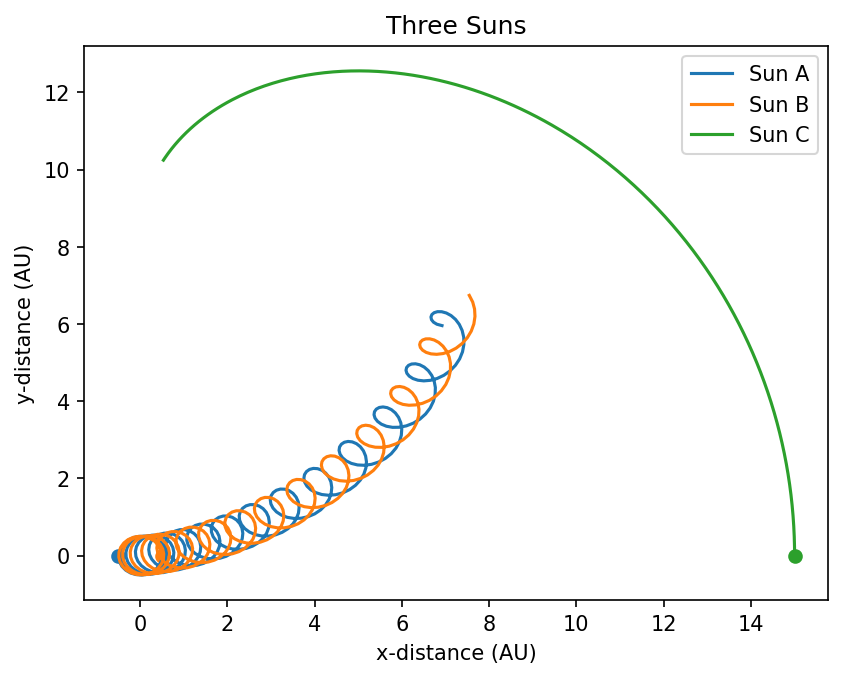

Num of evals: 2042
Initial Energy: -22.3769584693
Final Energy: -22.3783859293
Final Fractional Energy Drift: 0.0064%
Max Fractional Energy Drift: 0.0000637915
Total Absolute Cumulative Energy Drift: 0.01089


array([-22.37695847, -22.37695847, -22.37696086, -22.37696483,
       -22.37696906, -22.37697331, -22.37697754, -22.37698176,
       -22.37698597, -22.3769902 , -22.37699444, -22.37699871,
       -22.37700301, -22.37700733, -22.37701166, -22.37701598,
       -22.37702028, -22.37702455, -22.37702878, -22.37703298,
       -22.37703715, -22.37704131, -22.37704548, -22.37704968,
       -22.37705391, -22.37705816, -22.37706243, -22.37706671,
       -22.37707098, -22.37707524, -22.37707949, -22.37708371,
       -22.37708793, -22.37709215, -22.37709639, -22.37710065,
       -22.37710494, -22.37710926, -22.37711358, -22.37711791,
       -22.37712221, -22.37712649, -22.37713073, -22.37713493,
       -22.3771391 , -22.37714326, -22.37714743, -22.37715161,
       -22.37715583, -22.37716007, -22.37716434, -22.37716862,
       -22.3771729 , -22.37717718, -22.37718143, -22.37718566,
       -22.37718988, -22.3771941 , -22.37719833, -22.37720258,
       -22.37720686, -22.37721117, -22.37721549, -22.37

In [30]:
state0 = np.array([
    -0.5, 0, #M1 pos
    0.5, 0, #M2 pos
    15, 0, #M3 pos
    0, -np.sqrt(2) * np.pi, #M1 vel
    0, np.sqrt(2) * np.pi,  #M2 vel
    0, np.sqrt(G * 2 / 15), #M3 vel
])

M1 = 1 
M2 = 1
M3 = 1

masses = np.array([
    M1,
    M2,
    M3
])
ti, tf = 0, 10

sol = solve_ivp(derivs, (ti,tf), state0, rtol = 1e-10, args=(masses,))

m1_x, m1_y = sol.y[0], sol.y[1]
m2_x, m2_y = sol.y[2], sol.y[3]
m3_x, m3_y = sol.y[4], sol.y[5]

plt.plot(m1_x, m1_y, '-', label = "Sun A")
plt.plot(m2_x, m2_y, '-', label = "Sun B")
plt.plot(m3_x, m3_y, '-', label = "Sun C")
plt.scatter(m1_x[0], m1_y[0])
plt.scatter(m2_x[0], m2_y[0])
plt.scatter(m3_x[0], m3_y[0])
plt.xlabel("x-distance (AU)")
plt.ylabel("y-distance (AU)")
plt.legend()
plt.title("Three Suns")
plt.show()

print(f"Num of evals: {sol.nfev}")
energy_drift(sol, masses)

### Start Function

In [31]:
def start(a_p, angle):
    MA, MB, MC = 1.0, 1.0, 1.0
    p_mass = 3e-6
    masses = np.array([MA, MB, MC, p_mass])
    angle = np.deg2rad(angle)

    ma_x, ma_y = -0.5, 0
    mb_x, mb_y = 0.5,0

    # We have radius of a_p away from the center of mass
    # Therefore the x coordinate should be a_p*cos(angle)
    # And the y coordinate should be a_p*sin(angle)
    # And this should be offset by the center of mass coordinates

    p_x, p_y = a_p * np.cos(angle), a_p * np.sin(angle)

    x_cm = (ma_x*MA + mb_x*MB)/(MA+MB)
    y_cm = (ma_y*MA + mb_y*MB)/(MA+MB)

    p_x += x_cm
    p_y += y_cm

    v_circ = np.sqrt(G*(MA+MB) / a_p)

    # Take the negative reciprocal of v_circ * np.cos(angle) and v_circ * np.sin(angle) to convert from a normal pointing vector to a tangential velocity vector
    p_vx = -v_circ * np.sin(angle)
    p_vy = v_circ * np.cos(angle)

    positions = np.array([
    ma_x, ma_y,  # M1 pos
    mb_x, mb_y,  # M2 pos
    15.0, 0.0,  # M3 pos
    p_x, p_y  # Planet pos
    ])

    velocities = np.array([
    0.0, -np.sqrt(2) * np.pi,  # M1 vel
    0.0, np.sqrt(2) * np.pi,  # M2 vel
    0.0, np.sqrt(G * 2 / 15.0),  # M3 vel
    p_vx, p_vy,  # Planet vel
    ])

    # The M1 and M2 velocities are determined by the relative speed formula np.sqrt(G(MA+MB)/d), with result of np.sqrt(2G) = 2*sqrt(2)*pi
    # Half of that velocity goes to MA and the other half goes to MB, in opposite directions.

    state = np.concatenate([positions, velocities])

    return state, masses

### COM Frame transfer

I use the Center of Mass frame transfer equations<sup>2,3</sup>:

$$M = \sum m_i$$

$$R_{\text{CM}} = \frac{\sum m_i \vec{r}_i}{M}$$

$$V_{\text{CM}} = \frac{\sum m_i \vec{v}_i}{M}$$


$$r' = r - R_{\text{CM}}$$

$$v' = v - V_{\text{CM}}$$

2. https://users.physics.ox.ac.uk/~harnew/lectures/lecture6-mechanics-handout.pdf
3. https://phys.libretexts.org/Bookshelves/Classical_Mechanics/Variational_Principles_in_Classical_Mechanics_(Cline)/02%3A_Review_of_Newtonian_Mechanics/2.07%3A_Center_of_Mass_of_a_Many-Body_System

In [32]:
def com(masses, sol):
    MA, MB, MC, MD = masses
    
    ma_x, ma_y = sol.y[0], sol.y[1]
    mb_x, mb_y = sol.y[2], sol.y[3]
    mc_x, mc_y = sol.y[4], sol.y[5]
    md_x, md_y = sol.y[6], sol.y[7]

    ma_vx, ma_vy = sol.y[8], sol.y[9]
    mb_vx, mb_vy = sol.y[10], sol.y[11]
    mc_vx, mc_vy = sol.y[12], sol.y[13]
    md_vx, md_vy = sol.y[14], sol.y[15]
    
    CM = np.sum(masses)

    # COM Coordinates
    R_CM_x = 1/CM * (
        MA * ma_x +
        MB * mb_x +
        MC * mc_x +
        MD * md_x
    )

    R_CM_y = 1/CM * (
        MA * ma_y +
        MB * mb_y +
        MC * mc_y +
        MD * md_y
    )
    # Transfering to COM coordinates
    com_a_x = ma_x - R_CM_x
    com_b_x = mb_x - R_CM_x
    com_c_x = mc_x - R_CM_x
    com_d_x = md_x - R_CM_x

    com_a_y = ma_y - R_CM_y
    com_b_y = mb_y - R_CM_y
    com_c_y = mc_y - R_CM_y
    com_d_y = md_y - R_CM_y

    # COM Velocity
    v_CM_x = 1/CM * (
        MA*ma_vx +
        MB*mb_vx +
        MC*mc_vx +
        MD*md_vx
    )

    v_CM_y = 1/CM * (
        MA*ma_vy +
        MB*mb_vy +
        MC*mc_vy +
        MD*md_vy
    )
    # Transfering to COM velocity
    com_a_vx = ma_vx - v_CM_x
    com_b_vx = mb_vx - v_CM_x
    com_c_vx = mc_vx - v_CM_x
    com_d_vx = md_vx - v_CM_x

    com_a_vy = ma_vy - v_CM_y
    com_b_vy = mb_vy - v_CM_y
    com_c_vy = mc_vy - v_CM_y
    com_d_vy = md_vy - v_CM_y
    
    com_sol = copy(sol)
    com_sol.y = np.array([
        com_a_x, com_a_y, com_b_x, com_b_y,
        com_c_x, com_c_y, com_d_x, com_d_y,
        com_a_vx, com_a_vy, com_b_vx, com_b_vy,
        com_c_vx, com_c_vy, com_d_vx, com_d_vy,
    ])

    return com_sol

### 250 Year Run

In [33]:
state0, masses = start(3, 0)

In [34]:
def AB_crossing(t, state, masses):
    A_x, A_y = state[0], state[1]
    B_x, B_y = state[2], state[3]

    return B_y - A_y

AB_crossing.direction = 1
AB_crossing.terminal = False

In [35]:
ti, tf = 0, 250

sol = solve_ivp(derivs, (ti,tf), state0, rtol = 1e-10, args=(masses,), events = AB_crossing)

ma_x, ma_y = sol.y[0], sol.y[1]
mb_x, mb_y = sol.y[2], sol.y[3]
mc_x, mc_y = sol.y[4], sol.y[5]
md_x, md_y = sol.y[6], sol.y[7]

com_sol = com(masses, sol)
ma_x_com, ma_y_com = com_sol.y[0], com_sol.y[1]
mb_x_com, mb_y_com = com_sol.y[2], com_sol.y[3]
mc_x_com, mc_y_com = com_sol.y[4], com_sol.y[5]
md_x_com, md_y_com = com_sol.y[6], com_sol.y[7]

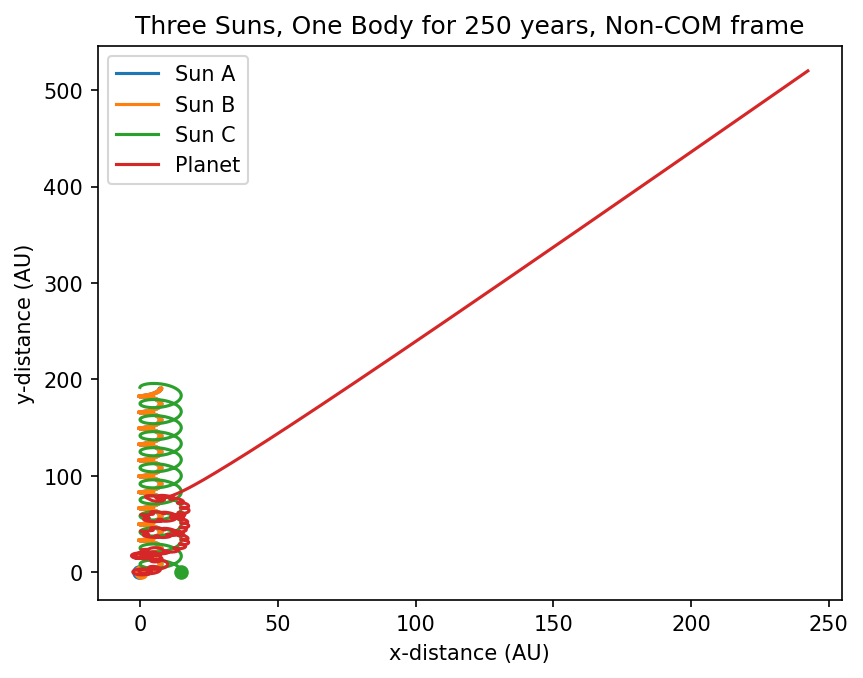

In [36]:
plt.plot(ma_x, ma_y, '-', label = "Sun A")
plt.plot(mb_x, mb_y, '-', label = "Sun B")
plt.plot(mc_x, mc_y, '-', label = "Sun C")
plt.plot(md_x, md_y, '-', label = "Planet")
plt.scatter(ma_x[0], ma_y[0])
plt.scatter(mb_x[0], mb_y[0])
plt.scatter(mc_x[0], mc_y[0])
plt.scatter(md_x[0], md_y[0], s=4)
plt.xlabel("x-distance (AU)")
plt.ylabel("y-distance (AU)")
plt.legend()
plt.title("Three Suns, One Body for 250 years, Non-COM frame")
plt.show()

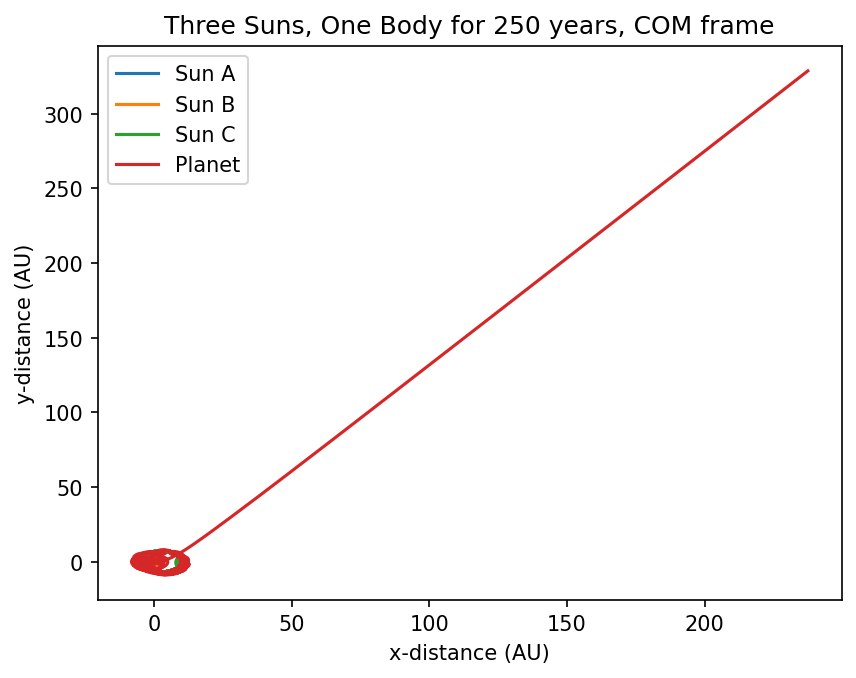

In [37]:
plt.plot(ma_x_com, ma_y_com, '-', label = "Sun A")
plt.plot(mb_x_com, mb_y_com, '-', label = "Sun B")
plt.plot(mc_x_com, mc_y_com, '-', label = "Sun C")
plt.plot(md_x_com, md_y_com, '-', label = "Planet")
plt.scatter(ma_x_com[0], ma_y_com[0])
plt.scatter(mb_x_com[0], mb_y_com[0])
plt.scatter(mc_x_com[0], mc_y_com[0])
plt.scatter(md_x_com[0], md_y_com[0], s=4)
plt.xlabel("x-distance (AU)")
plt.ylabel("y-distance (AU)")
plt.legend()
plt.title("Three Suns, One Body for 250 years, COM frame")
plt.show()

### A-B Checks

#### Distance Check

In [38]:
# ma_x, ma_y, mb_x, mb_y
# Initial distance
AB_distance = np.sqrt(
    (ma_x - mb_x) **2 +
    (ma_y - mb_y) **2
)
print(AB_distance)

[1.         1.00000107 1.00001571 ... 0.9976182  0.99836344 0.9986666 ]


In [39]:
print(f"Initial A-B distance: {AB_distance[0]:0.5f}")
print(f"Final A-B distance: {AB_distance[-1]:0.5f}")
print(f"Minimum A-B distance: {np.min(AB_distance):0.5}")
print(f"Maximum A-B distance: {np.max(AB_distance):0.5f}")

Initial A-B distance: 1.00000
Final A-B distance: 0.99867
Minimum A-B distance: 0.99652
Maximum A-B distance: 1.00182


The A-B seperation began at 1 AU, but varied between 0.99652 AU and 1.00182 AU. These deviations were caused by pertubations from Sun C, the smaller planet, as well as numerical errors.

#### Period and Kepler Check

Kepler's Third Law is $$T^2=\frac{a^3}{M_A+M_B}$$
$a = 1$ because the two suns are initialized with circular velocity with respect to a center of mass at their midpoint. They are placed initially 1 AU apart.

$M_A = M_B = 1$
$$
\begin{aligned}
T &= \sqrt{\frac{1^3}{1+1}} \\
  &= \sqrt{\frac{1}{2}} \\
  &\approx 0.7071 \text{ years}
\end{aligned}
$$

To compare the numerical period, an event is created to check for when Sun A and Sun B horizontally cross in one direction (negative to positive), i.e, have the same y value.

In [40]:
T_an = np.sqrt(1/2)
crossings = sol.t_events[0]
AB_periods = np.diff(crossings)

print(f"Analytical Period: {T_an:0.5f} years")
print(f"Initial A-B period: {AB_periods[0]:0.5f} years")
print(f"Final A-B period: {AB_periods[-1]:0.5f} years")
print(f"Minimum A-B period: {np.min(AB_periods):0.5f} years")
print(f"Maximum A-B period: {np.max(AB_periods):0.5f} years")

Analytical Period: 0.70711 years
Initial A-B period: 0.70697 years
Final A-B period: 0.70529 years
Minimum A-B period: 0.70463 years
Maximum A-B period: 0.70779 years


The period of A-B also does not vary very much from the analytical period of 0.70711 years. The maximum period is 0.70779 years, while the minimum period is around 0.70697 years. These variations are the results of gravitational effects from Sun C and the planet.

#### Energy, Momentum, and Angular Momentum conservation

##### Energy Conservation

In [41]:
com_energies = energy_drift(com_sol, masses)

Initial Energy: -23.2543191352
Final Energy: -23.2997366068
Final Fractional Energy Drift: 0.1953%
Max Fractional Energy Drift: 0.0019530773
Total Absolute Cumulative Energy Drift: 8.36263


The energy drift percentage between the initial and final state of the system is around 0.2%, after 250 years. This shows that the model is accurate.

##### Momentum Conservation

In [42]:
def total_momentum(state, masses):
    N = len(masses)
    vel = state[2*N:].reshape(N, 2)
    p_x = 0
    p_y = 0

    for i in range(0,N):
        m_i = masses[i]

        v_x = vel[i][0]
        v_y = vel[i][1]

        p_x += m_i * v_x
        p_y += m_i * v_y

    return np.array([p_x, p_y])

In [43]:
def momentum_drift(sol, masses):
    momentum = []
    num_time = len(sol.t)

    for k in range(num_time):
        state_k = sol.y[:, k] #accessing the model state at the specific timestep we are currently at
        momentum.append(total_momentum(state_k, masses))

    momentum = np.array(momentum)

    momentum_change = momentum - momentum[0]

    print(f"Initial Momentum: {momentum[0]}")
    print(f"Final Momentum: {momentum[-1]}")
    print(f"Final Momentum Change: {momentum_change[-1]}")

    return momentum, momentum_change

In [44]:
com_momentum, com_momentum_change = momentum_drift(com_sol, masses)
final_diff_scalar = np.sqrt(com_momentum_change[-1][0]**2 + com_momentum_change[-1][1]**2)
print(f"Final Momentum Change (scalar): {final_diff_scalar}")


Initial Momentum: [0.00000000e+00 2.76336029e-17]
Final Momentum: [ 5.37332291e-17 -2.94232988e-16]
Final Momentum Change: [ 5.37332291e-17 -3.21866591e-16]
Final Momentum Change (scalar): 3.263209495763394e-16


The final change in momentum is:
$\triangle p_x = 5.37\cdot10^{-17}$, $\triangle p_y = -3.22\cdot10^{-16}$, with overall scalar of $\triangle p = 3.26\cdot10^{-16}$

These values are extremely small and show the accuracy of the model.

##### Angular Momentum Conservation

The Angular Momentum formula<sup>4</sup> is:
$$L_z =  m(x v_y - y v_x)$$

4. https://www2.ph.ed.ac.uk/~ldeldebb/docs/QM/lect8.pdf

In [45]:
def total_angular_momentum(state, masses):
    N = len(masses)
    vel = state[2*N:].reshape(N, 2)
    pos = state[:2*N].reshape(N, 2)
    angular_momentum = 0

    for i in range(0,N):
        m_i = masses[i]

        x_i = pos[i][0]
        y_i = pos[i][1]

        v_x = vel[i][0]
        v_y = vel[i][1]

        angular_momentum += m_i * (x_i * v_y - y_i * v_x)

    return angular_momentum

In [46]:
def angular_drift(sol, masses):
    angular_momentum = []
    num_time = len(sol.t)

    for k in range(num_time):
        state_k = sol.y[:, k] #accessing the model state at the specific timestep we are currently at
        angular_momentum.append(total_angular_momentum(state_k, masses))

    angular_momentum = np.array(angular_momentum)

    angular_drift = np.abs((angular_momentum - angular_momentum[0]) / angular_momentum[0])

    print(f"Initial Angular Momentum: {angular_momentum[0]:.10f}")
    print(f"Final Angular Momentum: {angular_momentum[-1]:.10f}")
    print(f"Final Fractional Angular Momentum Drift: {angular_drift[-1]*100:0.4f}%")
    print(f"Max Fractional Angular Momentum Drift: {np.max(angular_drift):.10f}")
    print(f"Total Absolute Cumulative Angular Momentum Drift: {np.abs(np.sum(angular_drift)):.5f}")

    return angular_momentum

In [47]:
com_angular_momentum = angular_drift(com_sol, masses)

Initial Angular Momentum: 27.3858055838
Final Angular Momentum: 27.3807039907
Final Fractional Angular Momentum Drift: 0.0186%
Max Fractional Angular Momentum Drift: 0.0001862861
Total Absolute Cumulative Angular Momentum Drift: 0.79813


Angular Momentum is also well-conserved, with only a 0.0186% difference between initial and final angular momentum.

Conservation was tested for the complete Sun A, Sun B, Sun C, and planet system. Over the 250-year integration, the fractional changes in total energy and angular momentum were 0.1953% and  0.0186%, respectively, while the total momentum remained within 3.26e-16 of its initial centre-of-mass value. These small changes measure numerical integration error, and is evidence to support the model accuracy.

#### Planet Energy

The energy check mostly only checks the motion of the three suns, particularly the close A-B orbit, as well as the orbit of C around the A-B pair. Because the planet only has mass 3e-6, its kinetic and potential energy contributions are tiny. 

To check the planet's energy separately, we could use the energy per unit mass equation.
$$
\epsilon=\frac12v^2-\frac{GM}{r}
$$

## 4. The Planet's Story

In [48]:
state0, masses = start(5.6, 90)

In [49]:
ti, tf = 0, 600

sol = solve_ivp(derivs, (ti,tf), state0, rtol = 1e-10, args=(masses,), events = AB_crossing)

ma_x, ma_y = sol.y[0], sol.y[1]
mb_x, mb_y = sol.y[2], sol.y[3]
mc_x, mc_y = sol.y[4], sol.y[5]
md_x, md_y = sol.y[6], sol.y[7]

com_sol = com(masses, sol)
ma_x_com, ma_y_com = com_sol.y[0], com_sol.y[1]
mb_x_com, mb_y_com = com_sol.y[2], com_sol.y[3]
mc_x_com, mc_y_com = com_sol.y[4], com_sol.y[5]
md_x_com, md_y_com = com_sol.y[6], com_sol.y[7]

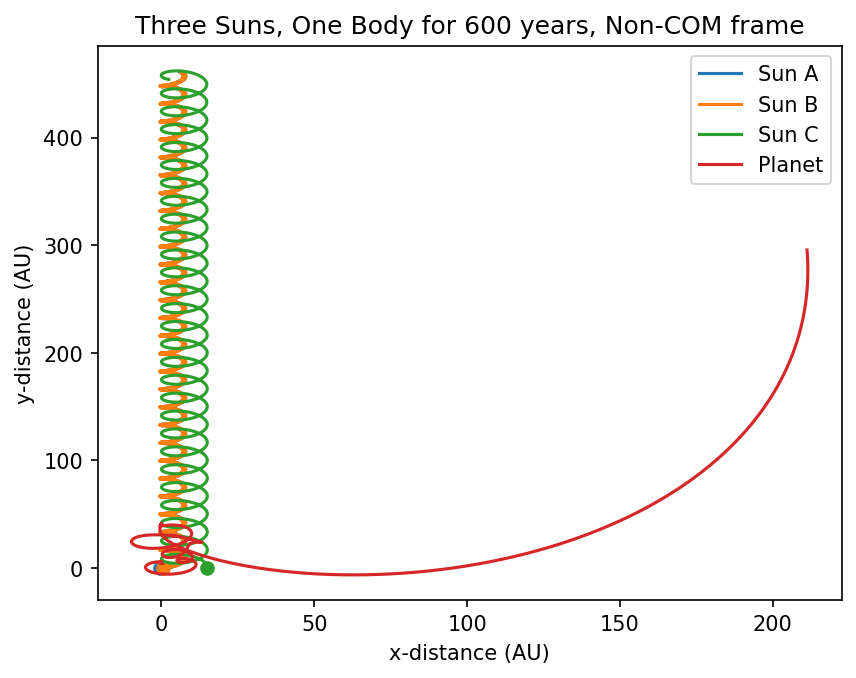

In [50]:
plt.plot(ma_x, ma_y, '-', label = "Sun A")
plt.plot(mb_x, mb_y, '-', label = "Sun B")
plt.plot(mc_x, mc_y, '-', label = "Sun C")
plt.plot(md_x, md_y, '-', label = "Planet")
plt.scatter(ma_x[0], ma_y[0])
plt.scatter(mb_x[0], mb_y[0])
plt.scatter(mc_x[0], mc_y[0])
plt.scatter(md_x[0], md_y[0], s=4)
plt.xlabel("x-distance (AU)")
plt.ylabel("y-distance (AU)")
plt.legend()
plt.title("Three Suns, One Body for 600 years, Non-COM frame")
plt.show()

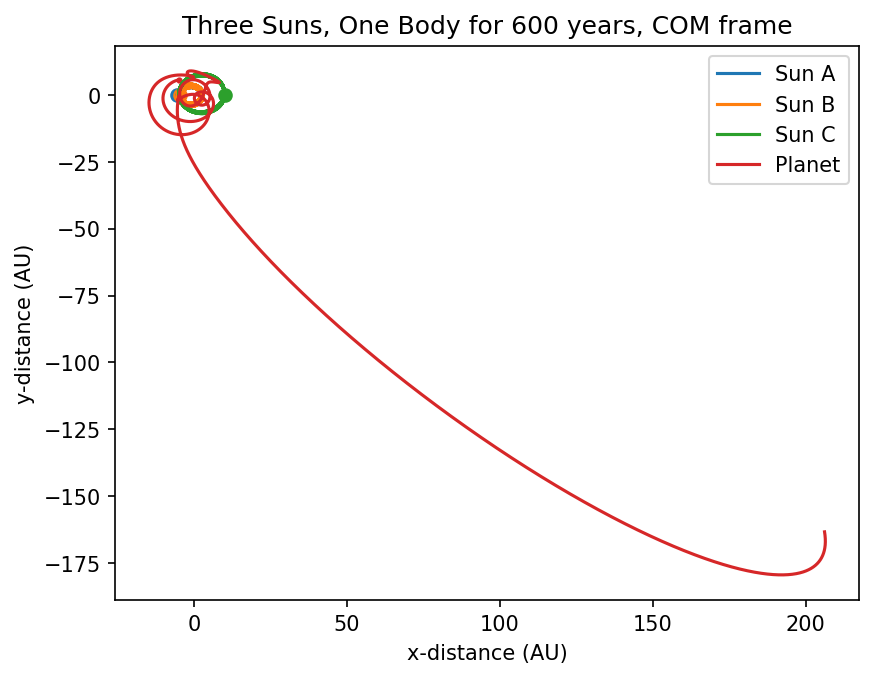

In [51]:
plt.plot(ma_x_com, ma_y_com, '-', label = "Sun A")
plt.plot(mb_x_com, mb_y_com, '-', label = "Sun B")
plt.plot(mc_x_com, mc_y_com, '-', label = "Sun C")
plt.plot(md_x_com, md_y_com, '-', label = "Planet")
plt.scatter(ma_x_com[0], ma_y_com[0])
plt.scatter(mb_x_com[0], mb_y_com[0])
plt.scatter(mc_x_com[0], mc_y_com[0])
plt.scatter(md_x_com[0], md_y_com[0], s=4)
plt.xlabel("x-distance (AU)")
plt.ylabel("y-distance (AU)")
plt.legend()
plt.title("Three Suns, One Body for 600 years, COM frame")
plt.show()

In [52]:
%matplotlib inline

### First 100 years

#### Orbital plot

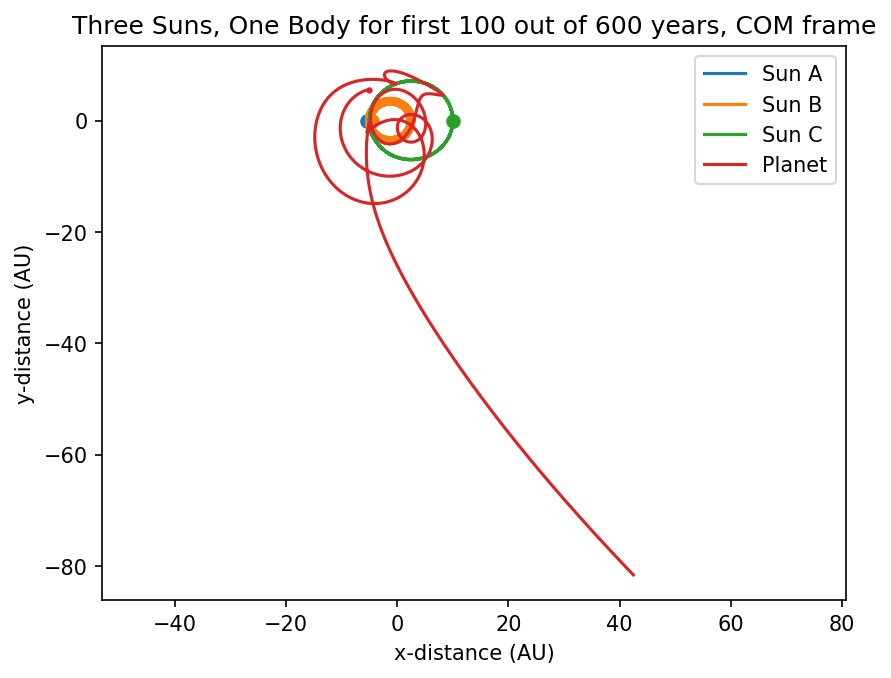

In [53]:
first_100 = sol.t <= 100
ma_x_c_100, ma_y_c_100 = ma_x_com[first_100], ma_y_com[first_100]
mb_x_c_100, mb_y_c_100 = mb_x_com[first_100], mb_y_com[first_100]
mc_x_c_100, mc_y_c_100 = mc_x_com[first_100], mc_y_com[first_100]
md_x_c_100, md_y_c_100 = md_x_com[first_100], md_y_com[first_100]

plt.plot(ma_x_c_100, ma_y_c_100, '-', label = "Sun A")
plt.plot(mb_x_c_100, mb_y_c_100, '-', label = "Sun B")
plt.plot(mc_x_c_100, mc_y_c_100, '-', label = "Sun C")
plt.plot(md_x_c_100, md_y_c_100, '-', label = "Planet")
plt.scatter(ma_x_com[0], ma_y_com[0])
plt.scatter(mb_x_com[0], mb_y_com[0])
plt.scatter(mc_x_com[0], mc_y_com[0])
plt.scatter(md_x_com[0], md_y_com[0], s=4)
plt.xlabel("x-distance (AU)")
plt.ylabel("y-distance (AU)")
plt.legend()
plt.title("Three Suns, One Body for first 100 out of 600 years, COM frame")
plt.axis("equal")
plt.show()


#### Planet distance from A+B centre

We calculate the location of the Centre of Mass between suns A and B using the formula<sup>5</sup>

$$r_{cm}=\frac{\sum m_i r_i}{\sum m_i}$$

5. https://isaacscience.org/concepts/cp_centre_mass

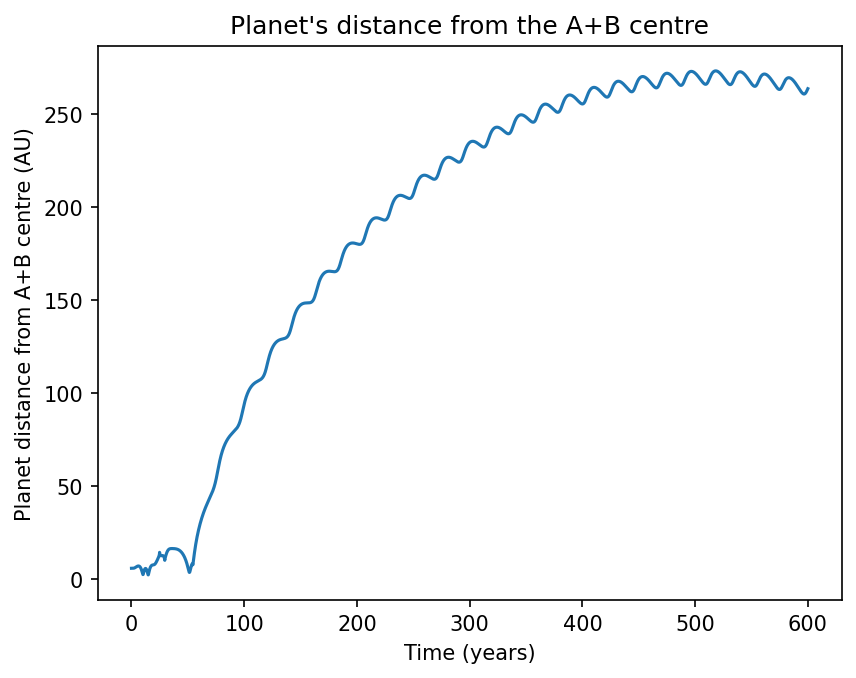

In [54]:
MA, MB = masses[0], masses[1]

AB_com_x = (MA * ma_x_com + MB * mb_x_com) / (MA + MB)
AB_com_y = (MA * ma_y_com + MB * mb_y_com) / (MA + MB)

planet_distance_AB = np.sqrt(
    (md_x_com - AB_com_x)**2 +
    (md_y_com - AB_com_y)**2
)

plt.plot(com_sol.t, planet_distance_AB)
plt.xlabel("Time (years)")
plt.ylabel("Planet distance from A+B centre (AU)")
plt.title("Planet's distance from the A+B centre")
plt.show()

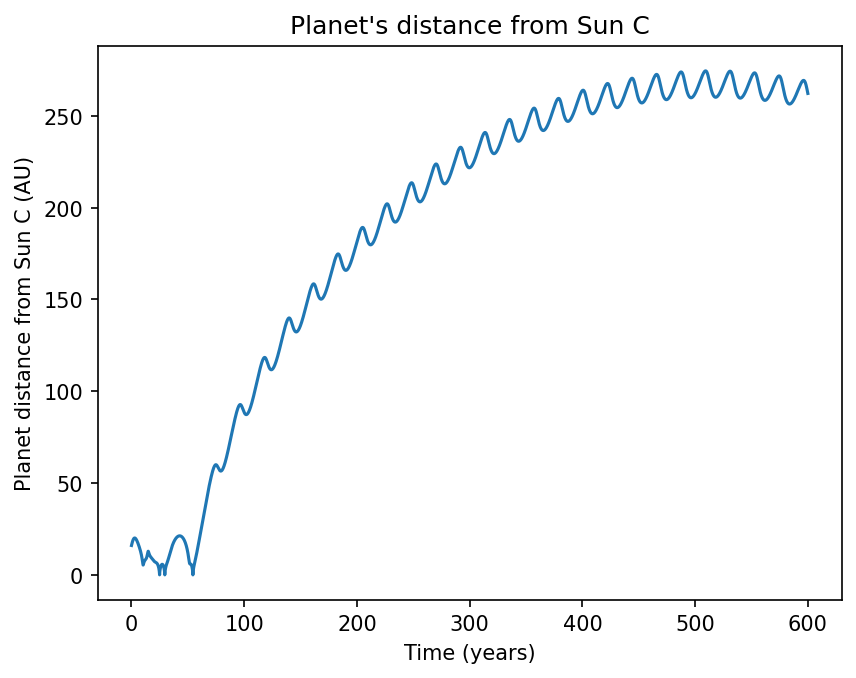

In [55]:
planet_distance_C = np.sqrt(
    (md_x_com - mc_x_com)**2 +
    (md_y_com - mc_y_com)**2
)

plt.plot(com_sol.t, planet_distance_C)
plt.xlabel("Time (years)")
plt.ylabel("Planet distance from Sun C (AU)")
plt.title("Planet's distance from Sun C")
plt.show()

### Bound to Pair, captured by C, or escaped

I look at the planet's energy per unit mass relative to the pair:
$$\epsilon=\tfrac12|\Delta\vec v_{p}|^2 - \frac{GM}{|\Delta\vec r|}$$

The velocity is calculated as the relative speed between the planet and the pair or C (depending on which we are looking at).

If the planet is bound by the A-B pair, $\epsilon_{AB} < 0$ AND the distance between the planet and A-B is less than than the distance between the planet and Sun C.

If the planet is bound by the A-B pair, $\epsilon_C < 0$ AND the distance between the planet and A-B is greater than the distance between the planet and Sun C.

If it is escaped, then $\epsilon_{AB} > 0$ and $\epsilon_{C} > 0$.

Being bound or captured results in a negative energy per unit mass because the magnitude of the gravitational potential energy is greater than the specific kinetic energy of the planet. When it is positive (escaped), that means the specific kinetic energy is greater than the gravitational potential energy.

In [56]:
def energy_status(sol, masses):
    N = len(masses)
    positions = sol.y[:2*N].reshape(N, 2, -1)
    velocities = sol.y[2*N:].reshape(N, 2, -1)

    MA, MB, MC, MP = masses

    AB_pos = (MA * positions[0] + MB * positions[1])/(MA + MB)
    AB_vel = (MA * velocities[0] + MB * velocities[1])/(MA + MB)

    planet_pos = positions[3]
    planet_vel = velocities[3]

    #Relative quantities for A-B pair and planet
    relative_pos_AB = planet_pos - AB_pos
    relative_vel_AB = planet_vel - AB_vel

    distance_AB = np.sqrt(
        relative_pos_AB[0] ** 2 + relative_pos_AB[1] ** 2
    )
    speed_AB = np.sqrt(
        relative_vel_AB[0] ** 2 + relative_vel_AB[1] ** 2
    )
    epsilon_AB = (0.5 * speed_AB**2) - G*(MA+MB) / distance_AB

    #Relative quantities for C and planet
    relative_pos_C = planet_pos - positions[2]
    relative_vel_C = planet_vel - velocities[2]

    distance_C = np.sqrt(
        relative_pos_C[0] ** 2 + relative_pos_C[1] ** 2
    )
    speed_C = np.sqrt(
        relative_vel_C[0] ** 2 + relative_vel_C[1] ** 2
    )
    epsilon_C = (0.5 * speed_C**2) - G*MC / distance_C

    escaped = (epsilon_AB > 0) & (epsilon_C > 0)
    bound_pair = (epsilon_AB < 0) & (distance_AB < distance_C)
    captured = (epsilon_C < 0) & (distance_AB > distance_C)

    return distance_AB, distance_C, epsilon_AB, epsilon_C, escaped, bound_pair, captured

In [57]:
distance_AB, distance_C, epsilon_AB, epsilon_C, escaped, bound_pair, captured = energy_status(com_sol, masses)

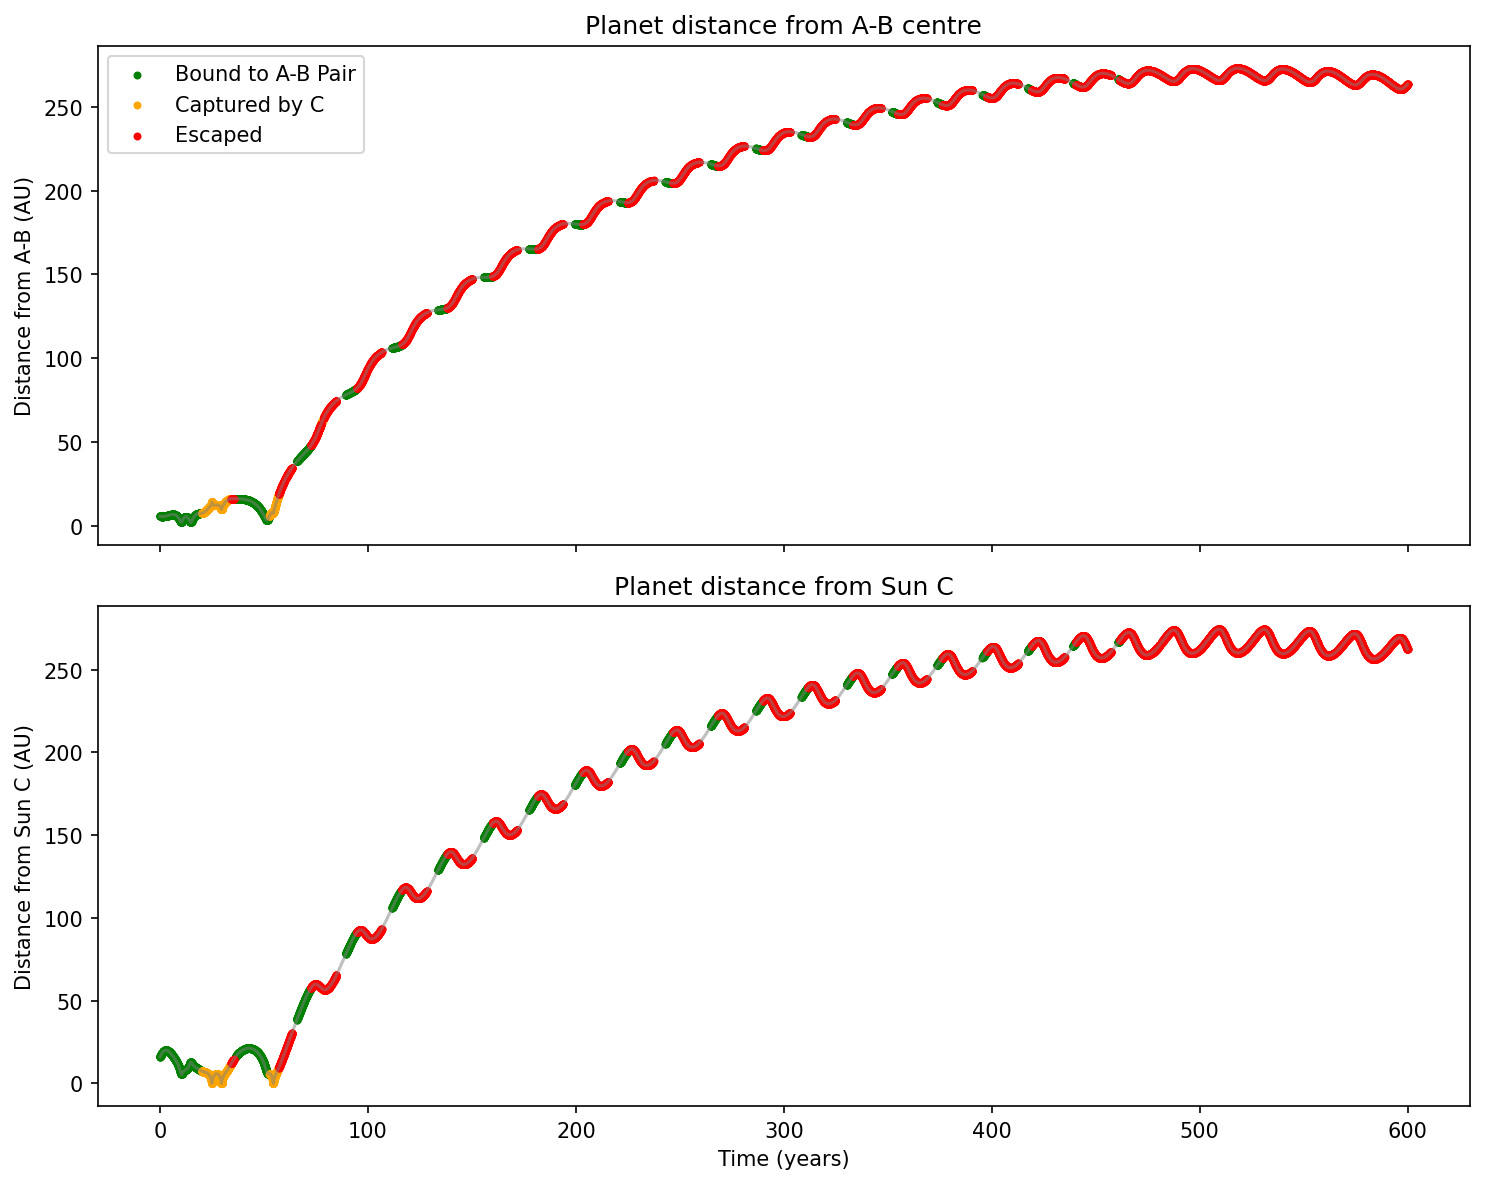

In [58]:
t = com_sol.t

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True
)

statuses = [
    (bound_pair, "Bound to A-B Pair", "green"),
    (captured, "Captured by C", "orange"),
    (escaped, "Escaped", "red")
]

# Distance from A-B centre
axes[0].plot(t, distance_AB, color="grey", alpha=0.5)

for status, label, color in statuses:
    axes[0].scatter(
        t[status],
        distance_AB[status], # Plots it for the specific points that are True 
        color=color,
        s=8,
        label=label
    )

axes[0].set_ylabel("Distance from A-B (AU)")
axes[0].set_title("Planet distance from A-B centre")
axes[0].legend()

# Distance from Sun C
axes[1].plot(t, distance_C, color="grey", alpha=0.5)

for status, label, color in statuses:
    axes[1].scatter(
        t[status],
        distance_C[status],
        color=color,
        s=8,
        label=label
    )

axes[1].set_xlabel("Time (years)")
axes[1].set_ylabel("Distance from Sun C (AU)")
axes[1].set_title("Planet distance from Sun C")

plt.tight_layout()
plt.show()

### rtol 100 times smaller

In [59]:
ti, tf = 0, 600

sol = solve_ivp(derivs, (ti,tf), state0, rtol = 1e-12, args=(masses,), events = AB_crossing)

com_sol_12 = com(masses, sol)

distance_AB_12, distance_C_12, epsilon_AB_12, epsilon_C_12, escaped_12, bound_pair_12, captured_12 = energy_status(com_sol_12, masses)

### rtol 100 times larger

In [60]:
ti, tf = 0, 600

sol = solve_ivp(derivs, (ti,tf), state0, rtol = 1e-8, args=(masses,), events = AB_crossing)

com_sol_8 = com(masses, sol)

distance_AB_8, distance_C_8, epsilon_AB_8, epsilon_C_8, escaped_8, bound_pair_8, captured_8 = energy_status(com_sol_8, masses)

### Comparison

In [61]:
ti, tf = 0, 600

sol = solve_ivp(derivs, (ti,tf), state0, rtol = 1e-10, args=(masses,), events = AB_crossing)

com_sol_10 = com(masses, sol)

distance_AB_10, distance_C_10, epsilon_AB_10, epsilon_C_10, escaped_10, bound_pair_10, captured_10 = energy_status(com_sol_10, masses)

In [62]:
runs = {
    "rtol = 1e-8": (
        com_sol_8.t,
        bound_pair_8,
        captured_8,
        escaped_8
    ),
    "rtol = 1e-10": (
        com_sol_10.t,
        bound_pair_10,
        captured_10,
        escaped_10
    ),
    "rtol = 1e-12": (
        com_sol_12.t,
        bound_pair_12,
        captured_12,
        escaped_12
    )
}

In [63]:
def entry_times(t, status):
    times = []
    was_active = False

    #True where status changes from False to True
    #status is a boolean array
    for i in range(len(status)):
        if (status[i] == True) and (was_active == False):
            times.append(t[i])
        was_active = status[i]

    return times

In [64]:
def total_time(t, status):
    total = 0

    for i in range(len(t) - 1):
        time_step = t[i + 1] - t[i]

        if status[i]:
            total += time_step

    return total

In [65]:
for rtol, (t, bound_pair, captured, escaped) in runs.items():
    print(f"\n{rtol}")

    print(
        "Bound to A+B:",
        entry_times(t, bound_pair)
    )

    print(
        "Captured by C:",
        entry_times(t, captured)
    )

    print(
        "Escaped:",
        entry_times(t, escaped)
    )


rtol = 1e-8
Bound to A+B: [np.float64(0.0), np.float64(36.39052269327339), np.float64(65.79408933186464), np.float64(89.35918131939879), np.float64(111.66690387008015), np.float64(133.72953258974798), np.float64(155.66857454438806), np.float64(177.5753354529894), np.float64(199.41706322669734), np.float64(221.25480532489664), np.float64(243.08781550116635), np.float64(264.8847301162727), np.float64(286.6761150071802), np.float64(308.46146204803887), np.float64(330.27093936316976), np.float64(352.04312971305677), np.float64(373.83911997891045), np.float64(395.59739300463895), np.float64(417.3792563200019), np.float64(439.1538506598141)]
Captured by C: [np.float64(20.014253734579658), np.float64(52.63055369431301), np.float64(77.48263743034282)]
Escaped: [np.float64(34.29448441975781), np.float64(57.06677649894714), np.float64(72.63898128588886), np.float64(78.6243025072406), np.float64(94.66542665496524), np.float64(116.47977785257468), np.float64(138.2654567832088), np.float64(159.988

In [66]:
for rtol, (t, bound_pair, captured, escaped) in runs.items():
    print(f"\n{rtol}")

    for name, status in [
        ("Bound to A+B", bound_pair),
        ("Captured by C", captured),
        ("Escaped", escaped)
    ]:
        times = entry_times(t, status)

        if len(times) > 0:
            print(f"Beginning {name} at {times[0]:.6f} year(s)")
        else:
            print(f"{name}: did not occur")



for rtol, (t, bound_pair, captured, escaped) in runs.items():
    print(f"\n{rtol}")

    statuses = [
        ("Bound to A-B Pair", bound_pair),
        ("Captured by C", captured),
        ("Escaped", escaped)
    ]

    for name, status in statuses:
        time_spent = total_time(t, status)
        print(f"Time {name}: {time_spent:.3f} years")


rtol = 1e-8
Beginning Bound to A+B at 0.000000 year(s)
Beginning Captured by C at 20.014254 year(s)
Beginning Escaped at 34.294484 year(s)

rtol = 1e-10
Beginning Bound to A+B at 0.000000 year(s)
Beginning Captured by C at 19.975700 year(s)
Beginning Escaped at 34.276166 year(s)

rtol = 1e-12
Beginning Bound to A+B at 0.000000 year(s)
Beginning Captured by C at 20.004868 year(s)
Beginning Escaped at 34.271622 year(s)

rtol = 1e-8
Time Bound to A-B Pair: 99.610 years
Time Captured by C: 19.858 years
Time Escaped: 388.926 years

rtol = 1e-10
Time Bound to A-B Pair: 101.746 years
Time Captured by C: 19.885 years
Time Escaped: 382.358 years

rtol = 1e-12
Time Bound to A-B Pair: 101.694 years
Time Captured by C: 19.869 years
Time Escaped: 383.155 years


All the times returned are very similar to each other. There are variations between them. For the times of first instances of statuses, the differences between the years are only less than a year. However, for longer time periods such as those for the total time spent in each state, the differences is only less than 2 years. 

Overall it is not an error because these slight differences are produced by the different number of evaluations needed for different tolerances.

## The Question

### Simulations

In [67]:
def survived(a_p):
    def event(t, state, masses):
        N = len(masses)
        positions = state[:2*N].reshape(N, 2)
        
        MA, MB, MC, MP = masses

        #COM of AB
        AB_pos = (MA * positions[0] + MB * positions[1])/(MA + MB)
        planet_pos = positions[3]
        planet_distance = planet_pos - AB_pos
        planet_d_scalar = np.sqrt(planet_distance[0] **2 + planet_distance[1]**2)

        # These values should be positive while inside a_p/3 and 3*a_p
        lower_limit = planet_d_scalar - a_p/3
        upper_limit = 3*a_p - planet_d_scalar

        return min(lower_limit, upper_limit) #if either of these are 0, that means the boundary has been crossed and the planet has escaped
    event.terminal = True
    event.direction = -1

    return event

In [68]:
a_ps = np.arange(1.5,6.75,0.25)
angles = np.array([0, 60, 120, 180, 240, 300])

In [69]:
survival = {}
for a_p in a_ps:
    for angle in angles:
        state, masses = start(a_p, angle)
        ti, tf = 0, 250    
        sol = solve_ivp(derivs, (ti,tf), state, rtol = 1e-10, args=(masses,), events = survived(a_p))

        survival[(a_p, angle)] = sol.t[-1] >= tf

        status = "survived" if survival[(a_p, angle)] else "escaped"
        print(f"a_p={a_p}, angle={angle}: {status}")

a_p=1.5, angle=0: escaped
a_p=1.5, angle=60: escaped
a_p=1.5, angle=120: escaped
a_p=1.5, angle=180: escaped
a_p=1.5, angle=240: escaped
a_p=1.5, angle=300: escaped
a_p=1.75, angle=0: escaped
a_p=1.75, angle=60: escaped
a_p=1.75, angle=120: escaped
a_p=1.75, angle=180: escaped
a_p=1.75, angle=240: escaped
a_p=1.75, angle=300: escaped
a_p=2.0, angle=0: escaped
a_p=2.0, angle=60: escaped
a_p=2.0, angle=120: escaped
a_p=2.0, angle=180: escaped
a_p=2.0, angle=240: escaped
a_p=2.0, angle=300: escaped
a_p=2.25, angle=0: survived
a_p=2.25, angle=60: survived
a_p=2.25, angle=120: escaped
a_p=2.25, angle=180: survived
a_p=2.25, angle=240: escaped
a_p=2.25, angle=300: survived
a_p=2.5, angle=0: survived
a_p=2.5, angle=60: survived
a_p=2.5, angle=120: survived
a_p=2.5, angle=180: escaped
a_p=2.5, angle=240: survived
a_p=2.5, angle=300: survived
a_p=2.75, angle=0: escaped
a_p=2.75, angle=60: escaped
a_p=2.75, angle=120: escaped
a_p=2.75, angle=180: escaped
a_p=2.75, angle=240: escaped
a_p=2.75, an

#### Graphing code for the multiple simulations

In [70]:
# survival = {}

# nrows = len(a_ps)
# ncols = 2 * len(angles)

# fig, axes = plt.subplots(
#     nrows,
#     ncols,
#     figsize=(30, 4 * nrows),
#     squeeze=False
# )

# fig.set_dpi(200)

# for i, a_p in enumerate(a_ps):
#     for j, angle in enumerate(angles):

#         state, masses = start(a_p, angle)
#         ti, tf = 0, 250

#         sol = solve_ivp(
#             derivs,
#             (ti, tf),
#             state,
#             rtol=1e-10,
#             args=(masses,),
#             events=survived(a_p)
#         )

#         ma_x, ma_y = sol.y[0], sol.y[1]
#         mb_x, mb_y = sol.y[2], sol.y[3]
#         mc_x, mc_y = sol.y[4], sol.y[5]
#         md_x, md_y = sol.y[6], sol.y[7]

#         com_sol = com(masses, sol)

#         ma_x_com, ma_y_com = com_sol.y[0], com_sol.y[1]
#         mb_x_com, mb_y_com = com_sol.y[2], com_sol.y[3]
#         mc_x_com, mc_y_com = com_sol.y[4], com_sol.y[5]
#         md_x_com, md_y_com = com_sol.y[6], com_sol.y[7]

#         survival[(a_p, angle)] = sol.t[-1] >= tf
#         status = ""
#         if survival[(a_p, angle)] == True:
#             status = "survived"
#         else:
#             status = "escaped"

#         print(f"a_p={a_p}, angle={angle}: {status}")

#         # Two adjacent columns for this run
#         noncom_ax = axes[i, 2*j]
#         com_ax = axes[i, 2*j + 1]

#         # Non-centre-of-mass frame
#         noncom_ax.plot(ma_x, ma_y, lw=0.5, label="Sun A")
#         noncom_ax.plot(mb_x, mb_y, lw=0.5, label="Sun B")
#         noncom_ax.plot(mc_x, mc_y, lw=0.5, label="Sun C")
#         noncom_ax.plot(md_x, md_y, lw=0.5, label="Planet")

#         noncom_ax.set_title(
#             f"a={a_p}, angle={angle}\nNon-COM ({status})",
#             fontsize=8
#         )
#         noncom_ax.set_aspect("equal", adjustable="box")
#         noncom_ax.tick_params(labelsize=7)

#         # Centre-of-mass frame
#         com_ax.plot(ma_x_com, ma_y_com, lw=0.5, label="Sun A")
#         com_ax.plot(mb_x_com, mb_y_com, lw=0.5, label="Sun B")
#         com_ax.plot(mc_x_com, mc_y_com, lw=0.5, label="Sun C")
#         com_ax.plot(md_x_com, md_y_com, lw=0.5, label="Planet")

#         com_ax.set_title(
#             f"a={a_p}, angle={angle}\nCOM ({status})",
#             fontsize=8
#         )
#         com_ax.set_aspect("equal", adjustable="box")
#         com_ax.tick_params(labelsize=7)

# # Add one shared legend instead of 126 repeated legends
# handles, labels = noncom_ax.get_legend_handles_labels()
# fig.legend(handles, labels, loc="upper center", ncol=4)

# fig.suptitle("Three-Sun Planet Survival Runs", fontsize=16)
# fig.tight_layout(rect=(0, 0, 1, 0.97))

# plt.show()

# fig.savefig(
#     "three_sun_survival_runs.pdf",
#     bbox_inches="tight"
# )

# fig.savefig(
#     "three_sun_survival_runs.svg",
#     bbox_inches="tight"
# )

# fig.savefig(
#     "three_sun_survival_runs.png",
#     dpi=300,
#     bbox_inches="tight"
# )

### Survival Fraction

In [71]:
survival_fraction = []

for a_p in a_ps:
    results = []
    for angle in angles:
        results.append(survival[(a_p, angle)]) #appending either T/F

    fraction = np.mean(results)
    survival_fraction.append(fraction)

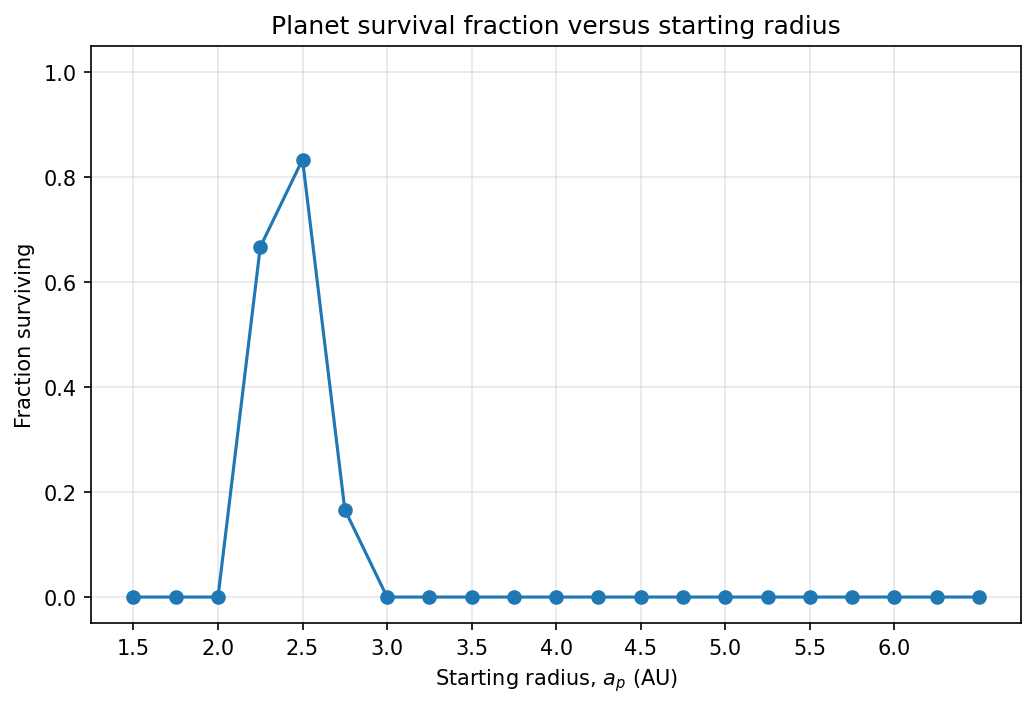

In [72]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(
    a_ps,
    survival_fraction,
    marker="o",
    linewidth=1.5
)

ax.set_xlabel(r"Starting radius, $a_p$ (AU)")
ax.set_ylabel("Fraction surviving")
ax.set_title("Planet survival fraction versus starting radius")

ax.set_ylim(-0.05, 1.05)
ax.set_yticks(np.linspace(0, 1, 6))
ax.set_xticks(np.arange(1.5, 6.5, 0.5))
ax.grid(True, alpha=0.3)

plt.show()

One run per radius isn't enough because a 3 Body system is chaotic, i.e, any small variations in starting conditions will yield vastly different outcomes. Therefore we should test different starting angles because some of those will yield different escape/stable results. For example, the graph above shows that for $a_p=2.5$ which has the most amount of stable orbits, out of the 6 starting angles, 5 resulted in a stable orbit while 1 escaped. The only difference between them are the angles. Therefore it is important to test this.

### Holman & Wiegert

The Holman & Wiegert<sup>6</sup> empirical stability formula estimates the critical semimajor axis ($a_c$), which is the approximate edge of long-term stable circular orbits.

#### P-Type
A planet around both suns of a pair (A+B) is called circumbinary/P-type. $a_{c,p}$ is the inner stability limit, i.e, orbits are typically stable if $a_c > a_{c,p}$. The following is the formula for the P-type orbit.

$$
a_{c,p} = \left(1.60 + 5.10e_{AB} - 2.22e_{AB}^2 + 4.12\mu_{AB} - 4.27e_{AB}\mu_{AB} - 5.09\mu_{AB}^2 + 4.61e_{AB}^2\mu_{AB}^2\right) a_{AB}.
$$

For A+B:

$$
a_{AB}=1\qquad \mu_{AB}=\frac{m_B}{m_A+m_B}=\frac{1}{2}\qquad e_{AB}=0.
$$

$e_{AB}$ measures the eccentricity of the A+B pair. Because A and B are in circular motion around their common centre of mass, the eccentricity is 0.

$$
a_{c,p} = \left(1.60 + 5.10(0) - 2.22(0)^2 + 4.12(0.5) - 4.27(0)(0.5) - 5.09(0.5)^2 + 4.61(0)^2(0.5)^2\right)(1).
$$
$$
a_{c,p} = 2.3875 \text{ AU}
$$

Thus planets outside 2.3875 AU are expected to orbit stably around A and B.

#### S-Type

Planets that orbit around one sun while a companion star orbits farther away is known as an S-Type or "circumstellar" orbit. We treat Sun A+B as one sun, with Sun C as its companion star. $a_{c,s}$ is the outer stability limit, meaning that orbits are typically stable for $a_c < a_{c,p}$. The following formula is:

$$
a_{c,s} = \left(0.464 - 0.380\mu - 0.631e_{\text{outer}} + 0.586\mu e_{\text{outer}} + 0.150e_{\text{outer}}^2 - 0.198\mu e_{\text{outer}}^2\right) a_{\text{outer}}
$$

For our system, we have:
$$a_{AB,C}=15\ \mathrm{AU},\qquad \mu=\frac{m_C}{m_A+m_B+m_C}=\frac{1}{3},\qquad e_{AB,C}=0.$$

$$
a_{c,s} = \left(0.464 - 0.380(\frac{1}{3}) - 0.631(0) + 0.586(1/3)(0) + 0.150(0)^2 - 0.198(\frac{1}{3}) (0)^2\right) (15)
$$

6. https://ui.adsabs.harvard.edu/abs/1999AJ....117..621H/abstract

In [73]:
a_cp = 1.6+4.12*0.5-5.09*0.5**2
a_cs = (0.464-0.380*(1/3))*15
print(f"P-Type inner stability orbit: {a_cp} AU")
print(f"S-Type outer stability orbit: {a_cs} AU")

P-Type inner stability orbit: 2.3875 AU
S-Type outer stability orbit: 5.0600000000000005 AU


Thus, planets that are orbiting the A+B pair are expected to remain stable between 2.39 AU and 5.06 AU, before Sun C disrupts them.

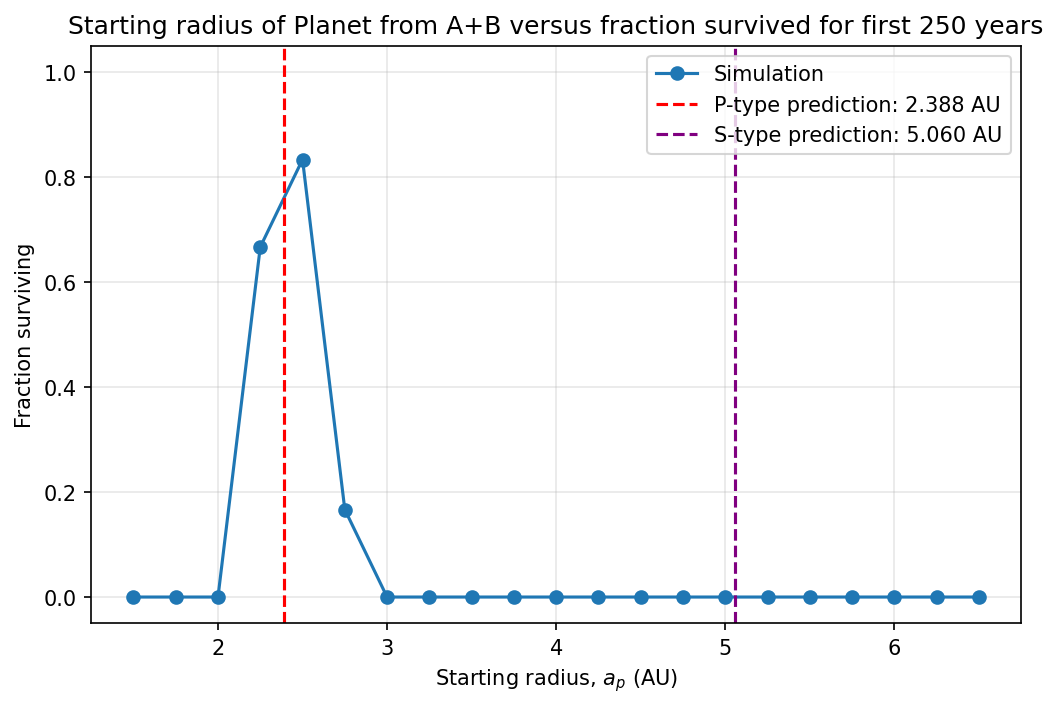

In [74]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(
    a_ps,
    survival_fraction,
    marker="o",
    label="Simulation"
)

ax.axvline(
    a_cp,
    color="red",
    linestyle="--",
    label=f"P-type prediction: {a_cp:0.3f} AU"
)

ax.axvline(
    a_cs,
    color="purple",
    linestyle="--",
    label=f"S-type prediction: {a_cs:0.3f} AU"
)

ax.set_xlabel(r"Starting radius, $a_p$ (AU)")
ax.set_ylabel("Fraction surviving")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Starting radius of Planet from A+B versus fraction survived for first 250 years")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

The P-type prediction matches quite well with my edge of around 2.25 AU. However, the right-side doesn't align well, because the formula assumes long-term orbital stability. However, my definition only evaluates stability as lying between $a_p/3$ and $3a_p$ for the first 250 years after the initial conditions. Thus there may be periods later on down the line where the planet is recaptured and kept in a stable orbit, but this occurs after the first 250 years.

### Sun C at 10 AU

P-Type inner stability orbit: 2.3875 AU
S-Type outer stability orbit: 3.373333333333334 AU
a_p=1.5, angle=0: escaped
a_p=1.5, angle=60: escaped
a_p=1.5, angle=120: escaped
a_p=1.5, angle=180: escaped
a_p=1.5, angle=240: escaped
a_p=1.5, angle=300: escaped
a_p=1.75, angle=0: escaped
a_p=1.75, angle=60: escaped
a_p=1.75, angle=120: escaped
a_p=1.75, angle=180: escaped
a_p=1.75, angle=240: escaped
a_p=1.75, angle=300: escaped
a_p=2.0, angle=0: escaped
a_p=2.0, angle=60: escaped
a_p=2.0, angle=120: escaped
a_p=2.0, angle=180: escaped
a_p=2.0, angle=240: escaped
a_p=2.0, angle=300: escaped
a_p=2.25, angle=0: escaped
a_p=2.25, angle=60: escaped
a_p=2.25, angle=120: escaped
a_p=2.25, angle=180: escaped
a_p=2.25, angle=240: escaped
a_p=2.25, angle=300: escaped
a_p=2.5, angle=0: escaped
a_p=2.5, angle=60: escaped
a_p=2.5, angle=120: escaped
a_p=2.5, angle=180: escaped
a_p=2.5, angle=240: escaped
a_p=2.5, angle=300: escaped
a_p=2.75, angle=0: escaped
a_p=2.75, angle=60: escaped
a_p=2.75, angle=1

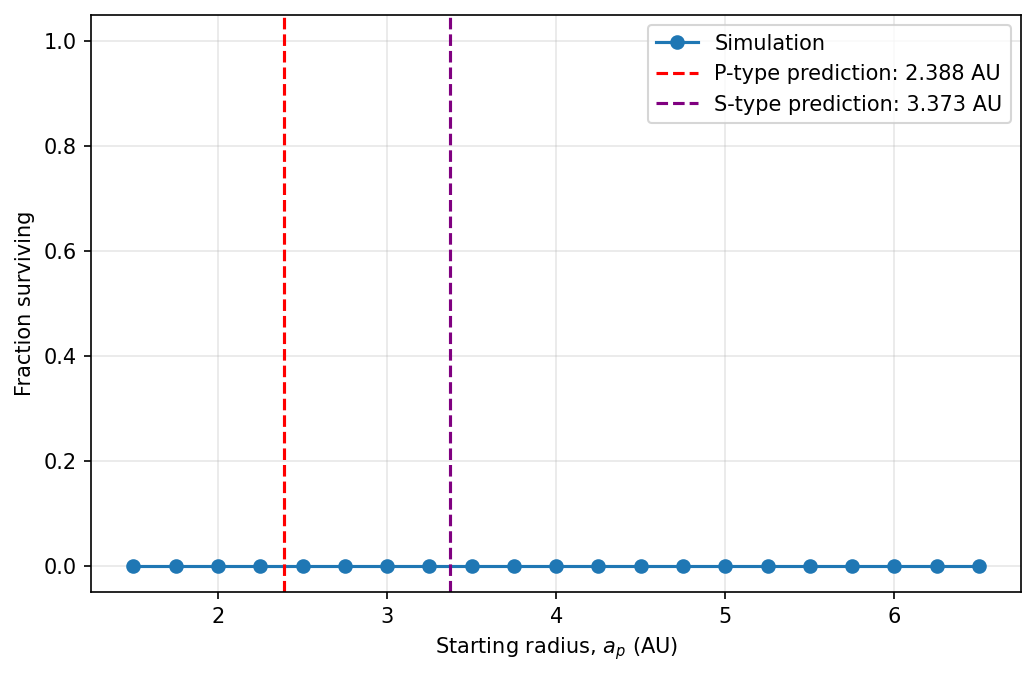

In [75]:
def start(a_p, angle):
    MA, MB, MC = 1.0, 1.0, 1.0
    p_mass = 3e-6
    masses = np.array([MA, MB, MC, p_mass])
    angle = np.deg2rad(angle)

    ma_x, ma_y = -0.5, 0
    mb_x, mb_y = 0.5,0

    # We have radius of a_p away from the center of mass
    # Therefore the x coordinate should be a_p*cos(angle)
    # And the y coordinate should be a_p*sin(angle)
    # And this should be offset by the center of mass coordinates

    p_x, p_y = a_p * np.cos(angle), a_p * np.sin(angle)

    x_cm = (ma_x*MA + mb_x*MB)/(MA+MB)
    y_cm = (ma_y*MA + mb_y*MB)/(MA+MB)

    p_x += x_cm
    p_y += y_cm

    v_circ = np.sqrt(G*(MA+MB) / a_p)

    # Take the negative reciprocal of v_circ * np.cos(angle) and v_circ * np.sin(angle) to convert from a normal pointing vector to a tangential velocity vector
    p_vx = -v_circ * np.sin(angle)
    p_vy = v_circ * np.cos(angle)

    positions = np.array([
    ma_x, ma_y,  # M1 pos
    mb_x, mb_y,  # M2 pos
    10.0, 0.0,  # M3 pos
    p_x, p_y  # Planet pos
    ])

    velocities = np.array([
    0.0, -np.sqrt(2) * np.pi,  # M1 vel
    0.0, np.sqrt(2) * np.pi,  # M2 vel
    0.0, np.sqrt(G * 2 / 10.0),  # M3 vel
    p_vx, p_vy,  # Planet vel
    ])

    # The M1 and M2 velocities are determined by the relative speed formula np.sqrt(G(MA+MB)/d), with result of np.sqrt(2G) = 2*sqrt(2)*pi
    # Half of that velocity goes to MA and the other half goes to MB, in opposite directions.

    state = np.concatenate([positions, velocities])

    return state, masses

a_cp = 1.6+4.12*0.5-5.09*0.5**2
a_cs = (0.464-0.380*(1/3))*10
print(f"P-Type inner stability orbit: {a_cp} AU")
print(f"S-Type outer stability orbit: {a_cs} AU")

survival = {}
for a_p in a_ps:
    for angle in angles:
        state, masses = start(a_p, angle)
        ti, tf = 0, 250    
        sol = solve_ivp(derivs, (ti,tf), state, rtol = 1e-10, args=(masses,), events = survived(a_p))

        survival[(a_p, angle)] = sol.t[-1] >= tf

        status = "survived" if survival[(a_p, angle)] else "escaped"
        print(f"a_p={a_p}, angle={angle}: {status}")

survival_fraction = []

for a_p in a_ps:
    results = []
    for angle in angles:
        results.append(survival[(a_p, angle)]) #appending either T/F

    fraction = np.mean(results)
    survival_fraction.append(fraction)

fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(
    a_ps,
    survival_fraction,
    marker="o",
    label="Simulation"
)

ax.axvline(
    a_cp,
    color="red",
    linestyle="--",
    label=f"P-type prediction: {a_cp:0.3f} AU"
)

ax.axvline(
    a_cs,
    color="purple",
    linestyle="--",
    label=f"S-type prediction: {a_cs:0.3f} AU"
)

ax.set_xlabel(r"Starting radius, $a_p$ (AU)")
ax.set_ylabel("Fraction surviving")
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.show()

### C at 20 AU

P-Type inner stability orbit: 2.3875 AU
S-Type outer stability orbit: 6.746666666666668 AU
a_p=1.5, angle=0: escaped
a_p=1.5, angle=60: escaped
a_p=1.5, angle=120: escaped
a_p=1.5, angle=180: escaped
a_p=1.5, angle=240: escaped
a_p=1.5, angle=300: escaped
a_p=1.75, angle=0: escaped
a_p=1.75, angle=60: escaped
a_p=1.75, angle=120: escaped
a_p=1.75, angle=180: escaped
a_p=1.75, angle=240: escaped
a_p=1.75, angle=300: escaped
a_p=2.0, angle=0: escaped
a_p=2.0, angle=60: escaped
a_p=2.0, angle=120: escaped
a_p=2.0, angle=180: escaped
a_p=2.0, angle=240: escaped
a_p=2.0, angle=300: escaped
a_p=2.25, angle=0: survived
a_p=2.25, angle=60: survived
a_p=2.25, angle=120: survived
a_p=2.25, angle=180: survived
a_p=2.25, angle=240: escaped
a_p=2.25, angle=300: survived
a_p=2.5, angle=0: survived
a_p=2.5, angle=60: survived
a_p=2.5, angle=120: survived
a_p=2.5, angle=180: survived
a_p=2.5, angle=240: survived
a_p=2.5, angle=300: survived
a_p=2.75, angle=0: survived
a_p=2.75, angle=60: survived
a_p=

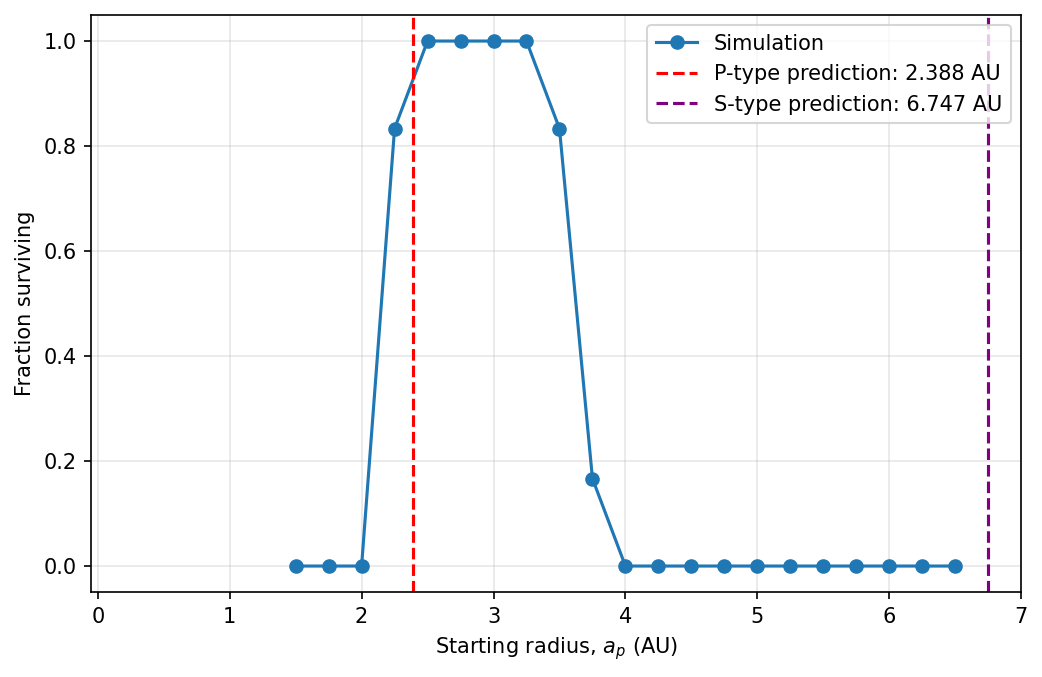

In [76]:
def start(a_p, angle):
    MA, MB, MC = 1.0, 1.0, 1.0
    p_mass = 3e-6
    masses = np.array([MA, MB, MC, p_mass])
    angle = np.deg2rad(angle)

    ma_x, ma_y = -0.5, 0
    mb_x, mb_y = 0.5,0

    # We have radius of a_p away from the center of mass
    # Therefore the x coordinate should be a_p*cos(angle)
    # And the y coordinate should be a_p*sin(angle)
    # And this should be offset by the center of mass coordinates

    p_x, p_y = a_p * np.cos(angle), a_p * np.sin(angle)

    x_cm = (ma_x*MA + mb_x*MB)/(MA+MB)
    y_cm = (ma_y*MA + mb_y*MB)/(MA+MB)

    p_x += x_cm
    p_y += y_cm

    v_circ = np.sqrt(G*(MA+MB) / a_p)

    # Take the negative reciprocal of v_circ * np.cos(angle) and v_circ * np.sin(angle) to convert from a normal pointing vector to a tangential velocity vector
    p_vx = -v_circ * np.sin(angle)
    p_vy = v_circ * np.cos(angle)

    positions = np.array([
    ma_x, ma_y,  # M1 pos
    mb_x, mb_y,  # M2 pos
    20.0, 0.0,  # M3 pos
    p_x, p_y  # Planet pos
    ])

    velocities = np.array([
    0.0, -np.sqrt(2) * np.pi,  # M1 vel
    0.0, np.sqrt(2) * np.pi,  # M2 vel
    0.0, np.sqrt(G * 2 / 20),  # M3 vel
    p_vx, p_vy,  # Planet vel
    ])

    # The M1 and M2 velocities are determined by the relative speed formula np.sqrt(G(MA+MB)/d), with result of np.sqrt(2G) = 2*sqrt(2)*pi
    # Half of that velocity goes to MA and the other half goes to MB, in opposite directions.

    state = np.concatenate([positions, velocities])

    return state, masses

a_cp = 1.6+4.12*0.5-5.09*0.5**2
a_cs = (0.464-0.380*(1/3))*20
print(f"P-Type inner stability orbit: {a_cp} AU")
print(f"S-Type outer stability orbit: {a_cs} AU")

survival = {}
for a_p in a_ps:
    for angle in angles:
        state, masses = start(a_p, angle)
        ti, tf = 0, 250    
        sol = solve_ivp(derivs, (ti,tf), state, rtol = 1e-10, args=(masses,), events = survived(a_p))

        survival[(a_p, angle)] = sol.t[-1] >= tf

        status = "survived" if survival[(a_p, angle)] else "escaped"
        print(f"a_p={a_p}, angle={angle}: {status}")

survival_fraction = []

for a_p in a_ps:
    results = []
    for angle in angles:
        results.append(survival[(a_p, angle)]) #appending either T/F

    fraction = np.mean(results)
    survival_fraction.append(fraction)

fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(
    a_ps,
    survival_fraction,
    marker="o",
    label="Simulation"
)

ax.axvline(
    a_cp,
    color="red",
    linestyle="--",
    label=f"P-type prediction: {a_cp:0.3f} AU"
)

ax.axvline(
    a_cs,
    color="purple",
    linestyle="--",
    label=f"S-type prediction: {a_cs:0.3f} AU"
)

ax.set_xlabel(r"Starting radius, $a_p$ (AU)")
ax.set_ylabel("Fraction surviving")
ax.set_ylim(-0.05, 1.05)
ax.set_xlim(-0.05, 7.00)
ax.grid(alpha=0.3)
ax.legend()

plt.show()

### Conclusion for moving C

As seen from the graphs produced, by moving Sun C to 10 AU, the survival rate drops to 0%, while moving it to 20 AU dramatically increases the number of overall survival rates, and also seeing 100% survival rate for 2.5 to 3.25 AU. This is because the outer stability limit changes. When C is closer, the limit decreases. When C is farther away, the limit increases, as there will be less pertubations coming from Sun C.

### Checking limits with rtol=1e-12

P-Type inner stability orbit: 2.3875 AU
S-Type outer stability orbit: 5.0600000000000005 AU
a_p=2.4875000000000003, angle=0: survived
a_p=2.4875000000000003, angle=60: escaped
a_p=2.4875000000000003, angle=120: escaped
a_p=2.4875000000000003, angle=180: survived
a_p=2.4875000000000003, angle=240: survived
a_p=2.4875000000000003, angle=300: survived
a_p=4.960000000000001, angle=0: escaped
a_p=4.960000000000001, angle=60: escaped
a_p=4.960000000000001, angle=120: escaped
a_p=4.960000000000001, angle=180: escaped
a_p=4.960000000000001, angle=240: escaped
a_p=4.960000000000001, angle=300: escaped


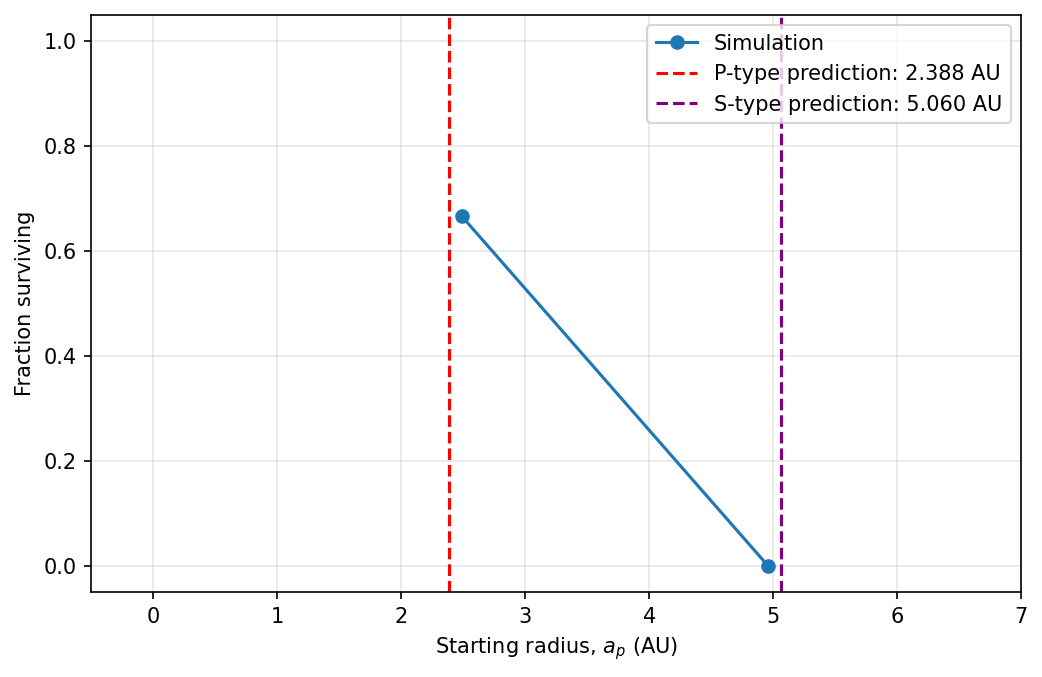

In [77]:
def start(a_p, angle):
    MA, MB, MC = 1.0, 1.0, 1.0
    p_mass = 3e-6
    masses = np.array([MA, MB, MC, p_mass])
    angle = np.deg2rad(angle)

    ma_x, ma_y = -0.5, 0
    mb_x, mb_y = 0.5,0

    # We have radius of a_p away from the center of mass
    # Therefore the x coordinate should be a_p*cos(angle)
    # And the y coordinate should be a_p*sin(angle)
    # And this should be offset by the center of mass coordinates

    p_x, p_y = a_p * np.cos(angle), a_p * np.sin(angle)

    x_cm = (ma_x*MA + mb_x*MB)/(MA+MB)
    y_cm = (ma_y*MA + mb_y*MB)/(MA+MB)

    p_x += x_cm
    p_y += y_cm

    v_circ = np.sqrt(G*(MA+MB) / a_p)

    # Take the negative reciprocal of v_circ * np.cos(angle) and v_circ * np.sin(angle) to convert from a normal pointing vector to a tangential velocity vector
    p_vx = -v_circ * np.sin(angle)
    p_vy = v_circ * np.cos(angle)

    positions = np.array([
    ma_x, ma_y,  # M1 pos
    mb_x, mb_y,  # M2 pos
    15.0, 0.0,  # M3 pos
    p_x, p_y  # Planet pos
    ])

    velocities = np.array([
    0.0, -np.sqrt(2) * np.pi,  # M1 vel
    0.0, np.sqrt(2) * np.pi,  # M2 vel
    0.0, np.sqrt(G * 2 / 15.0),  # M3 vel
    p_vx, p_vy,  # Planet vel
    ])

    # The M1 and M2 velocities are determined by the relative speed formula np.sqrt(G(MA+MB)/d), with result of np.sqrt(2G) = 2*sqrt(2)*pi
    # Half of that velocity goes to MA and the other half goes to MB, in opposite directions.

    state = np.concatenate([positions, velocities])

    return state, masses

a_cp = 1.6+4.12*0.5-5.09*0.5**2
a_cs = (0.464-0.380*(1/3))*15
print(f"P-Type inner stability orbit: {a_cp} AU")
print(f"S-Type outer stability orbit: {a_cs} AU")

survival = {}
for a_p in [a_cp+0.1, a_cs-0.1]:
    for angle in angles:
        state, masses = start(a_p, angle)
        ti, tf = 0, 250    
        sol = solve_ivp(derivs, (ti,tf), state, rtol = 1e-12, args=(masses,), events = survived(a_p))

        survival[(a_p, angle)] = sol.t[-1] >= tf

        status = "survived" if survival[(a_p, angle)] else "escaped"
        print(f"a_p={a_p}, angle={angle}: {status}")

survival_fraction = []

for a_p in [a_cp+0.1, a_cs-0.1]:
    results = []
    for angle in angles:
        results.append(survival[(a_p, angle)]) #appending either T/F

    fraction = np.mean(results)
    survival_fraction.append(fraction)

fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(
    [a_cp+0.1, a_cs-0.1],
    survival_fraction,
    marker="o",
    label="Simulation"
)

ax.axvline(
    a_cp,
    color="red",
    linestyle="--",
    label=f"P-type prediction: {a_cp:0.3f} AU"
)

ax.axvline(
    a_cs,
    color="purple",
    linestyle="--",
    label=f"S-type prediction: {a_cs:0.3f} AU"
)

ax.set_xlabel(r"Starting radius, $a_p$ (AU)")
ax.set_ylabel("Fraction surviving")
ax.set_ylim(-0.05, 1.05)
ax.set_xlim(-0.5,7)
ax.grid(alpha=0.3)
ax.legend()

plt.show()

No, my verdict doesn't change. Testing near the limits when C is at 15 AU shows similar results to the incremental testing previously simulated.

In [78]:
# def start(a_p, angle):
#     MA, MB, MC = 1.0, 1.0, 1.0
#     p_mass = 3e-6
#     masses = np.array([MA, MB, MC, p_mass])
#     angle = np.deg2rad(angle)

#     ma_x, ma_y = -0.5, 0
#     mb_x, mb_y = 0.5,0

#     # We have radius of a_p away from the center of mass
#     # Therefore the x coordinate should be a_p*cos(angle)
#     # And the y coordinate should be a_p*sin(angle)
#     # And this should be offset by the center of mass coordinates

#     p_x, p_y = a_p * np.cos(angle), a_p * np.sin(angle)

#     x_cm = (ma_x*MA + mb_x*MB)/(MA+MB)
#     y_cm = (ma_y*MA + mb_y*MB)/(MA+MB)

#     p_x += x_cm
#     p_y += y_cm

#     v_circ = np.sqrt(G*(MA+MB) / a_p)

#     # Take the negative reciprocal of v_circ * np.cos(angle) and v_circ * np.sin(angle) to convert from a normal pointing vector to a tangential velocity vector
#     p_vx = -v_circ * np.sin(angle)
#     p_vy = v_circ * np.cos(angle)

#     positions = np.array([
#     ma_x, ma_y,  # M1 pos
#     mb_x, mb_y,  # M2 pos
#     15.0, 0.0,  # M3 pos
#     p_x, p_y  # Planet pos
#     ])

#     velocities = np.array([
#     0.0, -np.sqrt(2) * np.pi,  # M1 vel
#     0.0, np.sqrt(2) * np.pi,  # M2 vel
#     0.0, np.sqrt(G * 2 / 15.0),  # M3 vel
#     p_vx, p_vy,  # Planet vel
#     ])

#     # The M1 and M2 velocities are determined by the relative speed formula np.sqrt(G(MA+MB)/d), with result of np.sqrt(2G) = 2*sqrt(2)*pi
#     # Half of that velocity goes to MA and the other half goes to MB, in opposite directions.

#     state = np.concatenate([positions, velocities])

#     return state, masses

In [79]:
# from IPython.display import HTML, display

# plt.rcParams["animation.embed_limit"] = 500

# # Select one initial condition to animate.
# a_p, angle = 2.25, 0
# state, masses = start(a_p, angle)
# ti, tf = 0, 250

# sol = solve_ivp(
#     derivs,
#     (ti, tf),
#     state,
#     rtol=1e-10,
#     args=(masses,),
#     events=survived(a_p)
# )

# com_sol = com(masses, sol)
# n_bodies = len(masses)
# noncom_data = sol.y[:2 * n_bodies].reshape(n_bodies, 2, -1)
# com_data = com_sol.y[:2 * n_bodies].reshape(n_bodies, 2, -1)
# frames = np.linspace(0, len(sol.t) - 1, 100, dtype=int)

# fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
# datasets = [noncom_data, com_data]
# titles = ["Non-centre-of-mass frame", "Centre-of-mass frame"]
# colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
# labels = ["Sun A", "Sun B", "Sun C", "Planet"]

# def axis_limits(data):
#     x_min, x_max = data[:, 0, :].min(), data[:, 0, :].max()
#     y_min, y_max = data[:, 1, :].min(), data[:, 1, :].max()
#     x_margin = max(0.05 * (x_max - x_min), 0.1)
#     y_margin = max(0.05 * (y_max - y_min), 0.1)
#     return (x_min - x_margin, x_max + x_margin), (y_min - y_margin, y_max + y_margin)

# trail_lines = []
# current_points = []
# for ax, data, title in zip(axes, datasets, titles):
#     x_limits, y_limits = axis_limits(data)
#     ax.set_xlim(x_limits)
#     ax.set_ylim(y_limits)
#     ax.set_aspect("equal", adjustable="box")
#     ax.set_xlabel("x-position (AU)")
#     ax.set_ylabel("y-position (AU)")
#     ax.set_title(title)

#     lines = []
#     points = []
#     for color, label in zip(colors, labels):
#         line, = ax.plot([], [], color=color, lw=0.8, label=label)
#         point, = ax.plot([], [], "o", color=color, ms=4)
#         lines.append(line)
#         points.append(point)
#     trail_lines.append(lines)
#     current_points.append(points)
#     ax.legend(loc="upper right", fontsize=8)

# time_text = fig.text(0.5, 0.01, "", ha="center")

# def update(frame):
#     for data, lines, points in zip(datasets, trail_lines, current_points):
#         for body in range(n_bodies):
#             lines[body].set_data(data[body, 0, :frame + 1], data[body, 1, :frame + 1])
#             points[body].set_data([data[body, 0, frame]], [data[body, 1, frame]])
#     time_text.set_text(f"time = {sol.t[frame]:.2f} years")
#     return [item for group in trail_lines + current_points for item in group] + [time_text]

# planet_survived = sol.t[-1] >= tf
# fig.suptitle(
#     f"Three suns and a planet: a_p={a_p} AU, angle={angle} degrees, "
#     f"{'survived' if planet_survived else 'escaped'}"
# )


In [80]:
# anim = animation.FuncAnimation(fig, update, frames=frames, interval=50, blit=True, repeat=True)
# from matplotlib.animation import PillowWriter

# anim.save(
#     "three_suns_animation.gif",
#     writer=PillowWriter(fps=30),
#     dpi=150
# )
# plt.close(fig)
# display(HTML(anim.to_jshtml()))